In [ ]:

from google.colab import files

uploaded = files.upload()


Saving PH2 Dataset images-20260929T174530Z-1-001.zip to PH2 Dataset images-20260929T174530Z-1-001.zip
Saving PH2_dataset.xlsx to PH2_dataset.xlsx


In [ ]:

import zipfile
import os

zip_path = '/content/PH2 Dataset images-20260929T174530Z-1-001.zip'

extract_path = '/content/PH2_dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [ ]:

dataset_path = '/content/PH2_dataset/PH2 Dataset images'

excel_path = '/content/PH2_dataset.xlsx'

print("Dataset folder exists:", os.path.exists(dataset_path))
print("Excel file exists:", os.path.exists(excel_path))


Dataset folder exists: True
Excel file exists: True


In [ ]:

import pandas as pd

df = pd.read_excel(excel_path, header=None)

records = df.iloc[12:].copy()

records = records[
    records[0].astype(str).str.match(r'IMD\d+')
]

def get_class(row):
    if pd.notna(row[2]):
        return 'Common Nevus'
    elif pd.notna(row[3]):
        return 'Atypical Nevus'
    elif pd.notna(row[4]):
        return 'Melanoma'
    return None

labels = pd.DataFrame({
    'Image_ID': records[0].values,
    'Class': records.apply(get_class, axis=1).values
})

labels = labels.dropna()

labels.to_csv('/content/PH2_labels.csv', index=False)

print(labels['Class'].value_counts())
print("Total images:", len(labels))


Class
Common Nevus      80
Atypical Nevus    80
Melanoma          40
Name: count, dtype: int64
Total images: 200


In [ ]:

import os

image_folders = [
    f for f in os.listdir(dataset_path)
    if f.startswith('IMD')
]

print("Total image folders:", len(image_folders))
print("\nFirst 10 folders:", image_folders[:10])


Total image folders: 200

First 10 folders: ['IMD304', 'IMD044', 'IMD384', 'IMD175', 'IMD242', 'IMD134', 'IMD371', 'IMD382', 'IMD284', 'IMD088']


Image shape: (576, 768, 3)
Mask shape: (576, 768)


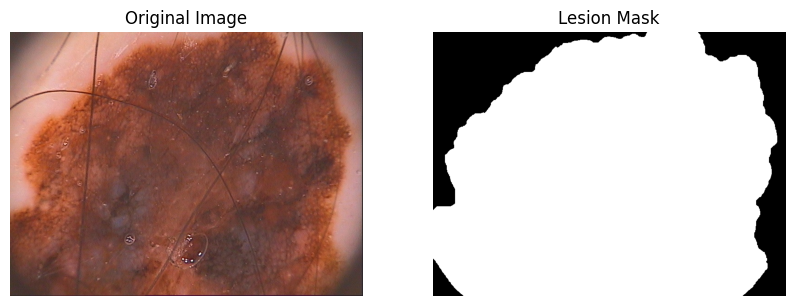

In [ ]:

import os
import cv2
import glob
import matplotlib.pyplot as plt

dataset_path = '/content/PH2_dataset/PH2 Dataset images'

def load_image_and_mask(image_id):

    folder = os.path.join(dataset_path, image_id)

    image_path = glob.glob(
        os.path.join(folder, '*_Dermoscopic_Image', '*.bmp')
    )[0]

    mask_path = glob.glob(
        os.path.join(folder, '*_lesion', '*.bmp')
    )[0]

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    return image, mask


# Test with one image
image, mask = load_image_and_mask('IMD419')

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

# Display image and mask
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title("Lesion Mask")
plt.axis('off')

plt.show()


In [ ]:

import numpy as np

print("Mask minimum:", np.min(mask))
print("Mask maximum:", np.max(mask))
print("Unique mask values:", np.unique(mask)[:20])

# Convert mask into binary form
binary_mask = (mask > 0).astype(np.uint8)

print("Lesion pixels:", np.sum(binary_mask))
print("Background pixels:", np.sum(binary_mask == 0))


Mask minimum: 0
Mask maximum: 255
Unique mask values: [  0 255]
Lesion pixels: 355453
Background pixels: 86915


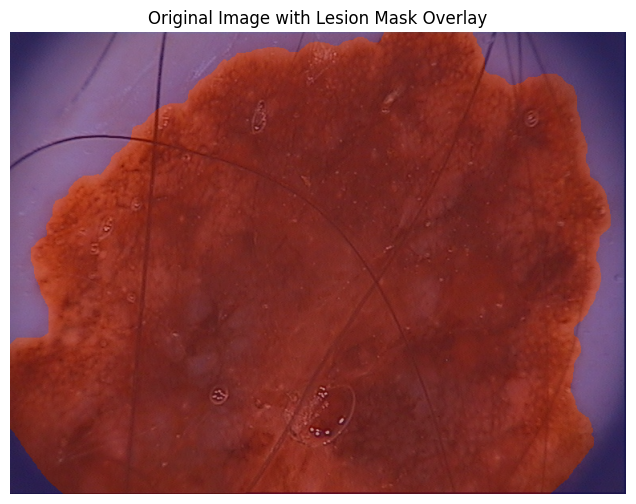

In [ ]:

plt.figure(figsize=(8, 6))

plt.imshow(image)
plt.imshow(binary_mask, cmap='jet', alpha=0.4)

plt.title("Original Image with Lesion Mask Overlay")
plt.axis('off')

plt.show()


In [ ]:

!pip install -q scikit-image

import os
import glob
import cv2
import numpy as np
import pandas as pd

from skimage.measure import label, regionprops


In [ ]:

def extract_shape_features(mask):

    # Convert mask into binary form
    binary = (mask > 0).astype(np.uint8)

    # Find connected components
    labeled_mask = label(binary)

    regions = regionprops(labeled_mask)

    if len(regions) == 0:
        return None

    # Select the largest lesion region
    region = max(regions, key=lambda r: r.area)

    # 1. Normalized Area
    normalized_area = region.area / binary.size

    # 2. Aspect Ratio
    major = region.major_axis_length
    minor = region.minor_axis_length

    aspect_ratio = major / minor if minor > 0 else 0

    # 3. Eccentricity
    eccentricity = region.eccentricity

    # 4. Solidity
    solidity = region.solidity

    # 5. Bilateral Asymmetry
    min_row, min_col, max_row, max_col = region.bbox

    cropped_mask = labeled_mask[
        min_row:max_row, min_col:max_col
    ] == region.label

    def asymmetry_score(original, reflected):

        intersection = np.sum(original & reflected)
        total = np.sum(original) + np.sum(reflected)

        dice = (2 * intersection / total) if total > 0 else 1

        return 1 - dice

    horizontal_asymmetry = asymmetry_score(
        cropped_mask, np.fliplr(cropped_mask)
    )

    vertical_asymmetry = asymmetry_score(
        cropped_mask, np.flipud(cropped_mask)
    )

    bilateral_asymmetry = (
        horizontal_asymmetry + vertical_asymmetry
    ) / 2

    return {
        'Normalized_Area': normalized_area,
        'Aspect_Ratio': aspect_ratio,
        'Eccentricity': eccentricity,
        'Solidity': solidity,
        'Bilateral_Asymmetry': bilateral_asymmetry
    }


In [ ]:

dataset_path = '/content/PH2_dataset/PH2 Dataset images'

image_folders = sorted([
    f for f in os.listdir(dataset_path)
    if f.startswith('IMD')
])

shape_results = []
failed_images = []

for image_id in image_folders:

    folder = os.path.join(dataset_path, image_id)

    mask_files = glob.glob(
        os.path.join(folder, '*_lesion', '*.bmp')
    )

    if not mask_files:
        failed_images.append(image_id)
        continue

    mask = cv2.imread(mask_files[0], cv2.IMREAD_GRAYSCALE)

    if mask is None:
        failed_images.append(image_id)
        continue

    features = extract_shape_features(mask)

    if features is None:
        failed_images.append(image_id)
        continue

    features['Image_ID'] = image_id

    shape_results.append(features)


shape_df = pd.DataFrame(shape_results)

# Save results
shape_df.to_csv(
    '/content/PH2_shape_features.csv',
    index=False
)

print("Successfully processed:", len(shape_df))
print("Failed images:", len(failed_images))

print("\nFirst five results:")
print(shape_df.head())


Successfully processed: 200
Failed images: 0

First five results:
   Normalized_Area  Aspect_Ratio  Eccentricity  Solidity  Bilateral_Asymmetry  \
0         0.274866      1.109920      0.433891  0.934654             0.107993   
1         0.113584      1.116628      0.444954  0.938507             0.110915   
2         0.194443      1.083975      0.385925  0.925440             0.107991   
3         0.147022      1.315419      0.649673  0.848690             0.233337   
4         0.117067      1.154250      0.499414  0.875784             0.130886   

  Image_ID  
0   IMD002  
1   IMD003  
2   IMD004  
3   IMD006  
4   IMD008  


In [ ]:

labels = pd.read_csv('/content/PH2_labels.csv')

final_shape_df = shape_df.merge(
    labels,
    on='Image_ID',
    how='left'
)

print("Missing labels:", final_shape_df['Class'].isna().sum())

final_shape_df.to_csv(
    '/content/PH2_shape_features_with_labels.csv',
    index=False
)

print(final_shape_df.head())


Missing labels: 0
   Normalized_Area  Aspect_Ratio  Eccentricity  Solidity  Bilateral_Asymmetry  \
0         0.274866      1.109920      0.433891  0.934654             0.107993   
1         0.113584      1.116628      0.444954  0.938507             0.110915   
2         0.194443      1.083975      0.385925  0.925440             0.107991   
3         0.147022      1.315419      0.649673  0.848690             0.233337   
4         0.117067      1.154250      0.499414  0.875784             0.130886   

  Image_ID           Class  
0   IMD002  Atypical Nevus  
1   IMD003    Common Nevus  
2   IMD004  Atypical Nevus  
3   IMD006  Atypical Nevus  
4   IMD008  Atypical Nevus  


In [ ]:

from google.colab import files

files.download('/content/PH2_shape_features_with_labels.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

def extract_border_features(mask):

    binary = (mask > 0).astype(np.uint8)

    # Find external lesion contour
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if len(contours) == 0:
        return None

    # Select largest contour
    contour = max(contours, key=cv2.contourArea)

    # Calculate area and perimeter
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    if area <= 0 or perimeter <= 0:
        return None

    # 1. Perimeter-to-area ratio
    perimeter_area_ratio = perimeter / area

    # 2. Circularity
    circularity = (4 * np.pi * area) / (perimeter ** 2)

    # 3. Radial distance variation
    moments = cv2.moments(contour)

    if moments['m00'] != 0:
        cx = moments['m10'] / moments['m00']
        cy = moments['m01'] / moments['m00']
    else:
        return None

    points = contour.reshape(-1, 2)

    distances = np.sqrt(
        (points[:, 0] - cx) ** 2 +
        (points[:, 1] - cy) ** 2
    )

    mean_distance = np.mean(distances)
    std_distance = np.std(distances)

    radial_variation = (
        std_distance / mean_distance
        if mean_distance > 0 else 0
    )

    return {
        'Perimeter_Area_Ratio': perimeter_area_ratio,
        'Circularity': circularity,
        'Radial_Distance_Variation': radial_variation
    }


In [ ]:

border_results = []
failed_border = []

for image_id in image_folders:

    folder = os.path.join(dataset_path, image_id)

    mask_files = glob.glob(
        os.path.join(folder, '*_lesion', '*.bmp')
    )

    if not mask_files:
        failed_border.append(image_id)
        continue

    mask = cv2.imread(
        mask_files[0],
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        failed_border.append(image_id)
        continue

    features = extract_border_features(mask)

    if features is None:
        failed_border.append(image_id)
        continue

    features['Image_ID'] = image_id

    border_results.append(features)


border_df = pd.DataFrame(border_results)

print("Successfully processed:", len(border_df))
print("Failed images:", len(failed_border))

print("\nFirst five border features:")
print(border_df.head())


Successfully processed: 200
Failed images: 0

First five border features:
   Perimeter_Area_Ratio  Circularity  Radial_Distance_Variation Image_ID
0              0.012323     0.691543                   0.098245   IMD002
1              0.018377     0.752008                   0.085541   IMD003
2              0.015407     0.624060                   0.086938   IMD004
3              0.020157     0.483224                   0.188277   IMD006
4              0.021269     0.542672                   0.110061   IMD008


In [ ]:

border_df = border_df.merge(
    labels,
    on='Image_ID',
    how='left'
)

border_df.to_csv(
    '/content/PH2_border_features.csv',
    index=False
)

print("\nClass distribution:")
print(border_df['Class'].value_counts())

print("\nMissing labels:",
      border_df['Class'].isna().sum())



Class distribution:
Class
Atypical Nevus    80
Common Nevus      80
Melanoma          40
Name: count, dtype: int64

Missing labels: 0


In [ ]:

from google.colab import files

files.download('/content/PH2_border_features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

def extract_color_features(image, mask):

    # Create binary lesion mask
    binary = mask > 0

    # Select lesion pixels only
    rgb_pixels = image[binary]

    if len(rgb_pixels) == 0:
        return None

    # Convert original RGB image into other color spaces
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    hsv_pixels = hsv[binary]
    lab_pixels = lab[binary]
    gray_pixels = gray[binary]

    features = {}

    # 1. RGB mean and standard deviation
    for i, channel in enumerate(['R', 'G', 'B']):
        features[f'RGB_Mean_{channel}'] = np.mean(rgb_pixels[:, i])
        features[f'RGB_Std_{channel}'] = np.std(rgb_pixels[:, i])

    # 2. HSV mean and standard deviation
    for i, channel in enumerate(['H', 'S', 'V']):
        features[f'HSV_Mean_{channel}'] = np.mean(hsv_pixels[:, i])
        features[f'HSV_Std_{channel}'] = np.std(hsv_pixels[:, i])

    # 3. Lab mean and standard deviation
    for i, channel in enumerate(['L', 'a', 'b']):
        features[f'Lab_Mean_{channel}'] = np.mean(lab_pixels[:, i])
        features[f'Lab_Std_{channel}'] = np.std(lab_pixels[:, i])

    # 4. Color nonuniformity using Lab distance
    lab_float = lab_pixels.astype(np.float32)

    mean_lab = np.mean(lab_float, axis=0)

    distances = np.sqrt(
        np.sum((lab_float - mean_lab) ** 2, axis=1)
    )

    features['Lab_Color_Nonuniformity'] = np.mean(distances)

    # 5. Dark pixel fraction
    dark_pixels = np.sum(gray_pixels < 50)

    features['Dark_Pixel_Fraction'] = (
        dark_pixels / len(gray_pixels)
    )

    return features


In [ ]:

color_results = []
failed_color = []

for image_id in image_folders:

    folder = os.path.join(dataset_path, image_id)

    image_files = glob.glob(
        os.path.join(folder, '*_Dermoscopic_Image', '*.bmp')
    )

    mask_files = glob.glob(
        os.path.join(folder, '*_lesion', '*.bmp')
    )

    if not image_files or not mask_files:
        failed_color.append(image_id)
        continue

    # Load RGB image
    image = cv2.imread(image_files[0])

    if image is None:
        failed_color.append(image_id)
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Load lesion mask
    mask = cv2.imread(
        mask_files[0],
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None or image.shape[:2] != mask.shape:
        failed_color.append(image_id)
        continue

    features = extract_color_features(image, mask)

    if features is None:
        failed_color.append(image_id)
        continue

    features['Image_ID'] = image_id

    color_results.append(features)


color_df = pd.DataFrame(color_results)

print("Successfully processed:", len(color_df))
print("Failed images:", len(failed_color))

print("\nFirst five color features:")
print(color_df.head())


Successfully processed: 200
Failed images: 0

First five color features:
   RGB_Mean_R  RGB_Std_R  RGB_Mean_G  RGB_Std_G  RGB_Mean_B  RGB_Std_B  \
0  146.887983  35.676724   85.672004  25.688268   56.100136  18.357995   
1  141.026145  25.825441   99.907090  22.949317   95.599948  21.811531   
2  136.924820  36.148565   92.118526  26.750631   85.315582  23.275674   
3  180.382363  24.212448  124.500070  18.317003   96.286900  20.660904   
4  201.663866  22.604624  149.321769  25.989153  112.572911  32.167402   

   HSV_Mean_H  HSV_Std_H  HSV_Mean_S  HSV_Std_S  ...  HSV_Std_V  Lab_Mean_L  \
0    9.544656   2.468103  158.288669  16.331759  ...  35.676724  108.898999   
1   22.352635  54.705180   83.767163  13.111595  ...  25.827418  118.152478   
2   14.368462  41.339613   96.434061  13.988438  ...  36.148565  110.950341   
3   11.639926  18.411401  118.353305  27.167699  ...  24.212448  145.928546   
4   12.196701   1.723139  115.518024  29.623595  ...  22.604624  168.191087   

   Lab_

In [ ]:

color_df = color_df.merge(
    labels,
    on='Image_ID',
    how='left'
)

color_df.to_csv(
    '/content/PH2_color_features.csv',
    index=False
)

print("Total color descriptors:", len(color_df.columns) - 2)

print("\nClass distribution:")
print(color_df['Class'].value_counts())

print("\nMissing labels:",
      color_df['Class'].isna().sum())


Total color descriptors: 20

Class distribution:
Class
Atypical Nevus    80
Common Nevus      80
Melanoma          40
Name: count, dtype: int64

Missing labels: 0


In [ ]:

from google.colab import files

files.download('/content/PH2_color_features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import cv2
import pandas as pd
import os
import glob


In [ ]:

def extract_texture_features(image, mask):

    # Convert RGB image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    binary = (mask > 0).astype(np.uint8)

    # Select lesion pixels
    lesion_pixels = gray[binary == 1]

    if len(lesion_pixels) == 0:
        return None

    features = {}

    # 1. Grayscale Entropy
    hist = np.bincount(
        lesion_pixels,
        minlength=256
    )

    probabilities = hist / hist.sum()

    probabilities = probabilities[probabilities > 0]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    features['Grayscale_Entropy'] = entropy

    # 2. Local Variance
    gray_float = gray.astype(np.float32)

    mean = cv2.boxFilter(
        gray_float,
        -1,
        (5, 5),
        normalize=True
    )

    mean_square = cv2.boxFilter(
        gray_float ** 2,
        -1,
        (5, 5),
        normalize=True
    )

    variance_map = np.maximum(
        mean_square - mean ** 2,
        0
    )

    features['Local_Variance'] = np.mean(
        variance_map[binary == 1]
    )

    # 3 and 4. GLCM Contrast and Homogeneity

    # Quantize grayscale image into 16 levels
    quantized = (gray // 16).astype(np.uint8)

    # Extract lesion bounding box
    ys, xs = np.where(binary == 1)

    y1, y2 = ys.min(), ys.max() + 1
    x1, x2 = xs.min(), xs.max() + 1

    roi = quantized[y1:y2, x1:x2]
    roi_mask = binary[y1:y2, x1:x2]

    contrast_values = []
    homogeneity_values = []

    # Horizontal and vertical neighboring pixels
    offsets = [(0, 1), (1, 0)]

    for dy, dx in offsets:

        h, w = roi.shape

        r1 = slice(0, h-dy)
        r2 = slice(dy, h)

        c1 = slice(0, w-dx)
        c2 = slice(dx, w)

        p1 = roi[r1, c1]
        p2 = roi[r2, c2]

        valid = (
            (roi_mask[r1, c1] == 1) &
            (roi_mask[r2, c2] == 1)
        )

        if not np.any(valid):
            continue

        a = p1[valid]
        b = p2[valid]

        # Calculate GLCM statistics
        differences = a.astype(float) - b.astype(float)

        contrast = np.mean(differences ** 2)

        homogeneity = np.mean(
            1 / (1 + differences ** 2)
        )

        contrast_values.append(contrast)
        homogeneity_values.append(homogeneity)

    features['GLCM_Contrast'] = np.mean(contrast_values)

    features['GLCM_Homogeneity'] = np.mean(
        homogeneity_values
    )

    # 5. Edge Density
    edges = cv2.Canny(gray, 50, 150)

    lesion_edges = edges[binary == 1]

    edge_density = np.sum(
        lesion_edges > 0
    ) / len(lesion_edges)

    features['Edge_Density'] = edge_density

    return features


In [ ]:

texture_results = []
failed_texture = []

for image_id in image_folders:

    folder = os.path.join(dataset_path, image_id)

    image_files = glob.glob(
        os.path.join(
            folder,
            '*_Dermoscopic_Image',
            '*.bmp'
        )
    )

    mask_files = glob.glob(
        os.path.join(
            folder,
            '*_lesion',
            '*.bmp'
        )
    )

    if not image_files or not mask_files:
        failed_texture.append(image_id)
        continue

    image = cv2.imread(image_files[0])

    if image is None:
        failed_texture.append(image_id)
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        mask_files[0],
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None or image.shape[:2] != mask.shape:
        failed_texture.append(image_id)
        continue

    features = extract_texture_features(
        image,
        mask
    )

    if features is None:
        failed_texture.append(image_id)
        continue

    features['Image_ID'] = image_id

    texture_results.append(features)


texture_df = pd.DataFrame(texture_results)

print("Successfully processed:", len(texture_df))
print("Failed images:", len(failed_texture))

print("\nFirst five texture features:")
print(texture_df.head())


Successfully processed: 200
Failed images: 0

First five texture features:
   Grayscale_Entropy  Local_Variance  GLCM_Contrast  GLCM_Homogeneity  \
0           6.642079       65.709114       0.390380          0.832272   
1           6.533016      167.018433       0.795210          0.753512   
2           6.805914       89.295479       0.485627          0.796221   
3           6.283343       29.621592       0.262816          0.872068   
4           6.517459       90.422752       0.398266          0.839614   

   Edge_Density Image_ID  
0      0.073190   IMD002  
1      0.182713   IMD003  
2      0.138823   IMD004  
3      0.025821   IMD006  
4      0.101700   IMD008  


In [ ]:

texture_df = texture_df.merge(
    labels,
    on='Image_ID',
    how='left'
)

print("\nClass distribution:")
print(texture_df['Class'].value_counts())

print("\nMissing labels:",
      texture_df['Class'].isna().sum())

texture_df.to_csv(
    '/content/PH2_texture_features.csv',
    index=False
)



Class distribution:
Class
Atypical Nevus    80
Common Nevus      80
Melanoma          40
Name: count, dtype: int64

Missing labels: 0


In [ ]:

from google.colab import files

files.download('/content/PH2_texture_features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Keep Image_ID and feature columns only.
# Class will be added once at the end.

shape_features = shape_df.drop(columns=['Class'], errors='ignore')
border_features = border_df.drop(columns=['Class'], errors='ignore')
color_features = color_df.drop(columns=['Class'], errors='ignore')
texture_features = texture_df.drop(columns=['Class'], errors='ignore')

# Merge all feature groups using Image_ID
master_df = shape_features.merge(
    border_features, on='Image_ID', how='inner',
    validate='one_to_one'
)

master_df = master_df.merge(
    color_features, on='Image_ID', how='inner',
    validate='one_to_one'
)

master_df = master_df.merge(
    texture_features, on='Image_ID', how='inner',
    validate='one_to_one'
)

# Add true class labels
master_df = master_df.merge(
    labels[['Image_ID', 'Class']],
    on='Image_ID',
    how='inner',
    validate='one_to_one'
)

print("Total images:", len(master_df))
print("Total columns:", len(master_df.columns))
print("Total descriptors:", len(master_df.columns) - 2)

print("\nClass distribution:")
print(master_df['Class'].value_counts())

print("\nMissing values:")
print(master_df.isnull().sum().sum())

print("\nFirst five records:")
print(master_df.head())


Total images: 200
Total columns: 35
Total descriptors: 33

Class distribution:
Class
Atypical Nevus    80
Common Nevus      80
Melanoma          40
Name: count, dtype: int64

Missing values:
0

First five records:
   Normalized_Area  Aspect_Ratio  Eccentricity  Solidity  Bilateral_Asymmetry  \
0         0.274866      1.109920      0.433891  0.934654             0.107993   
1         0.113584      1.116628      0.444954  0.938507             0.110915   
2         0.194443      1.083975      0.385925  0.925440             0.107991   
3         0.147022      1.315419      0.649673  0.848690             0.233337   
4         0.117067      1.154250      0.499414  0.875784             0.130886   

  Image_ID  Perimeter_Area_Ratio  Circularity  Radial_Distance_Variation  \
0   IMD002              0.012323     0.691543                   0.098245   
1   IMD003              0.018377     0.752008                   0.085541   
2   IMD004              0.015407     0.624060                   0.08693

In [ ]:

master_df.to_csv(
    '/content/PH2_Master_Features.csv',
    index=False
)

print("Master dataset saved successfully!")


Master dataset saved successfully!


In [ ]:

from google.colab import files

files.download('/content/PH2_Master_Features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

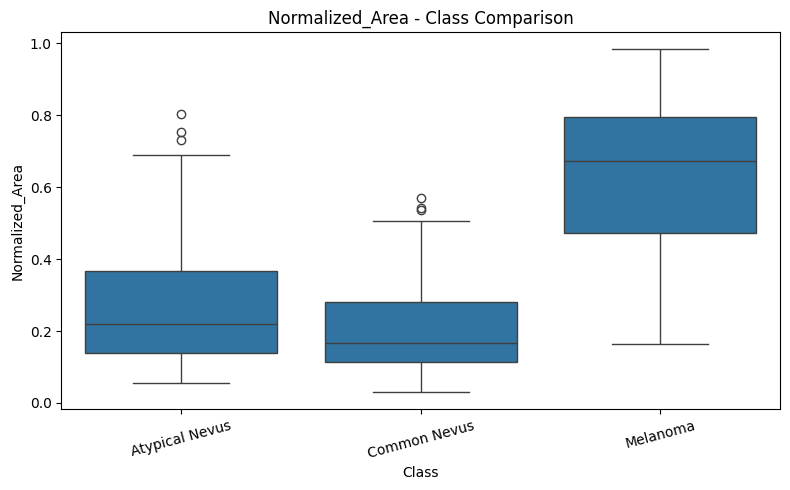

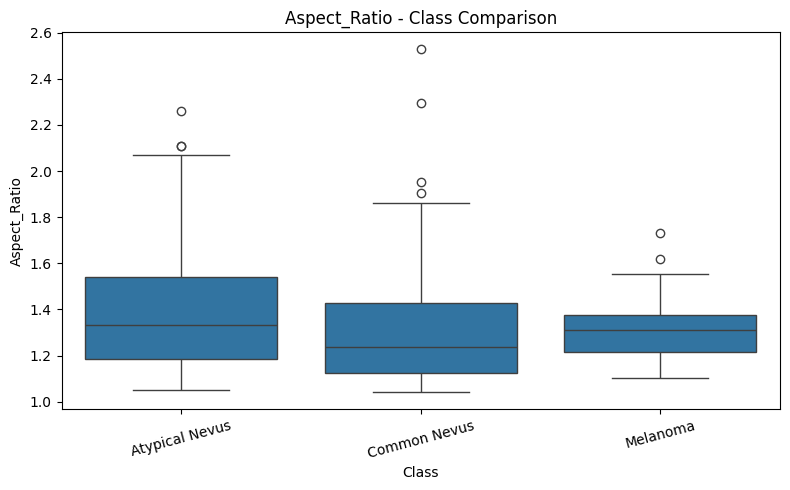

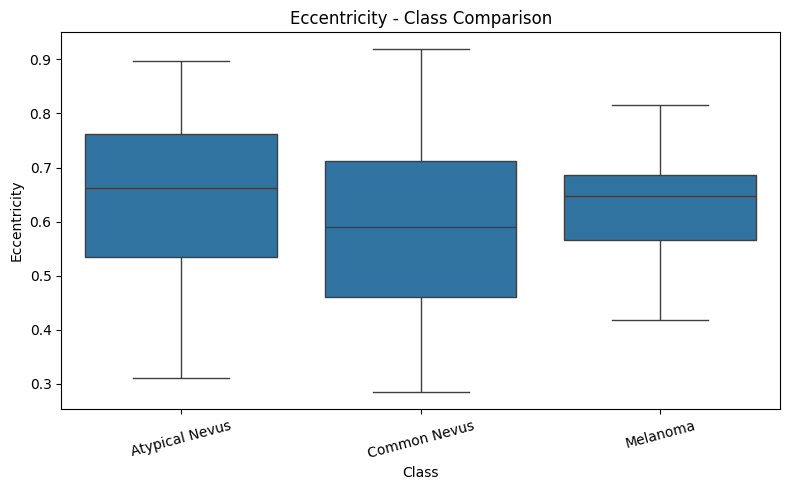

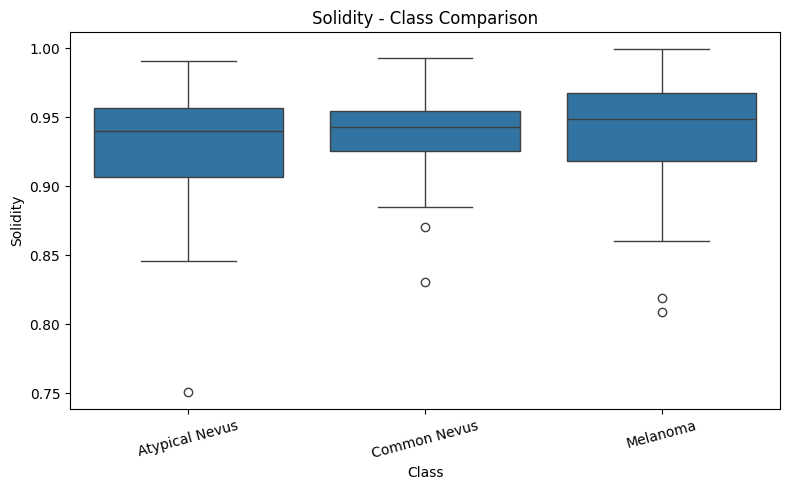

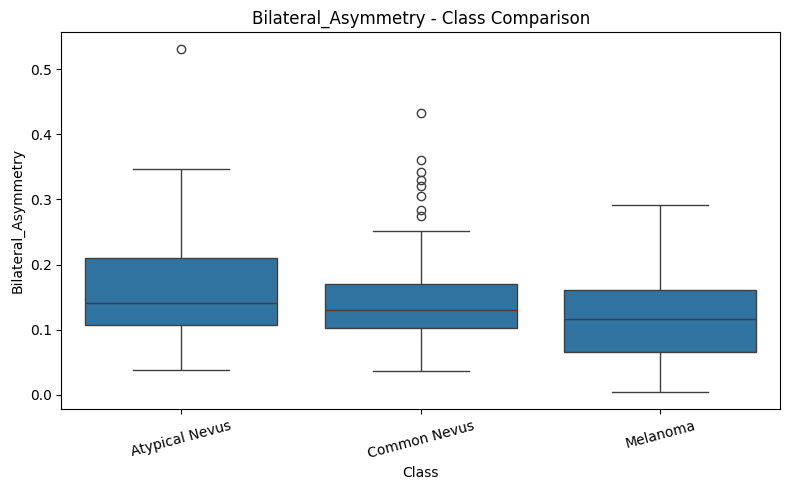

...

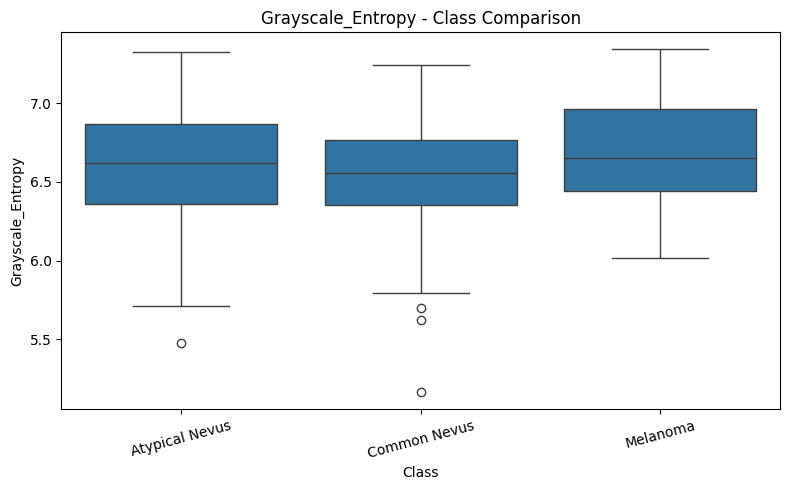

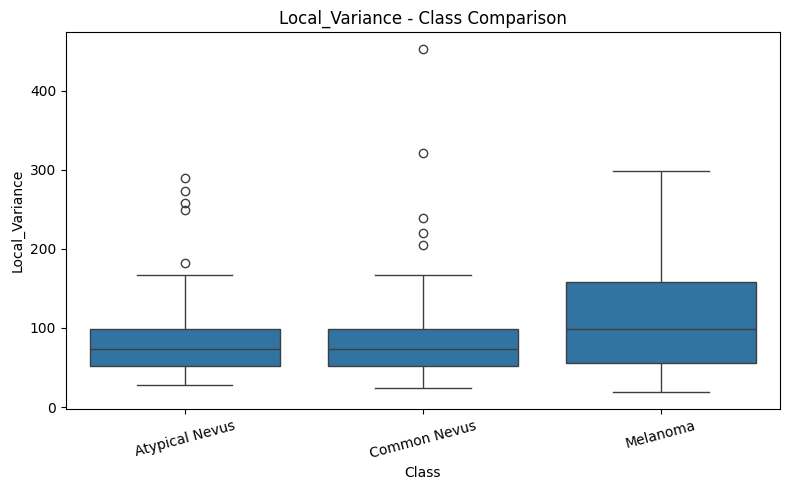

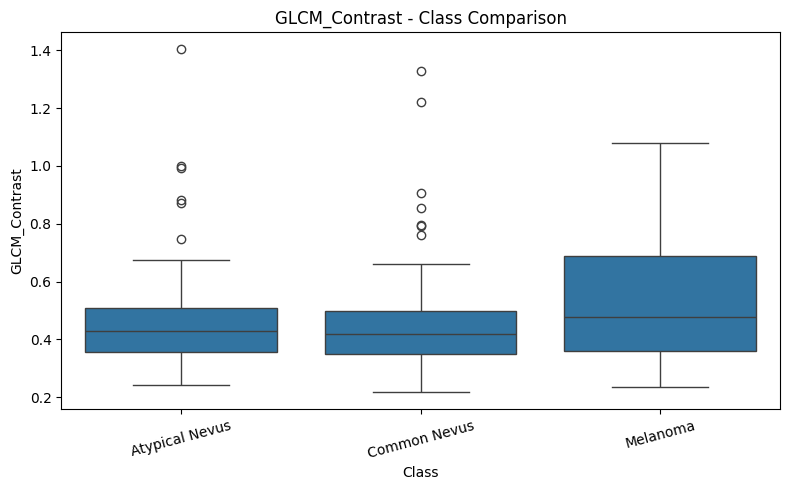

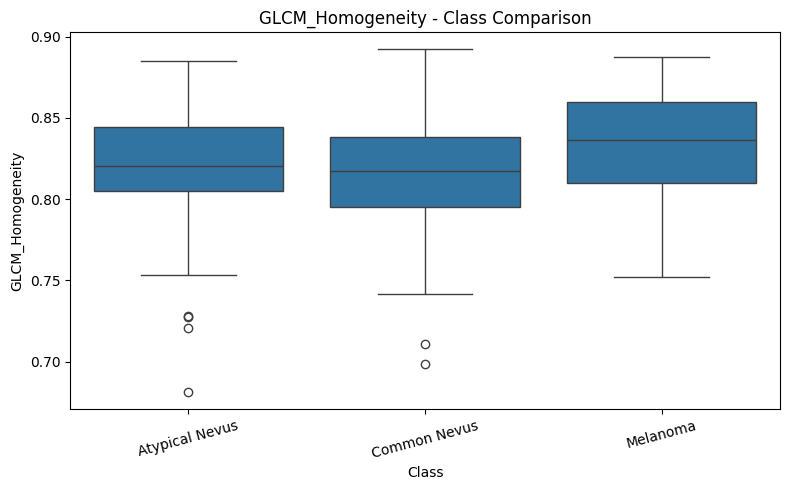

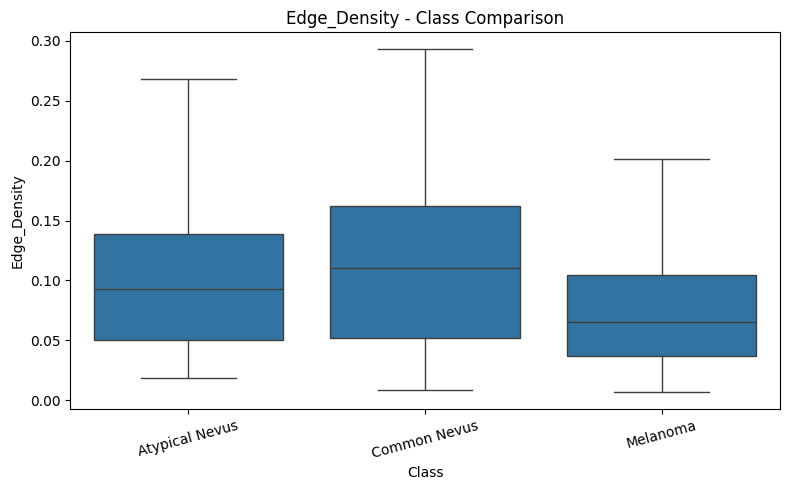

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

feature_columns = [
    col for col in master_df.columns
    if col not in ['Image_ID', 'Class']
]

for feature in feature_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=master_df,
        x='Class',
        y=feature
    )

    plt.title(f'{feature} - Class Comparison')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


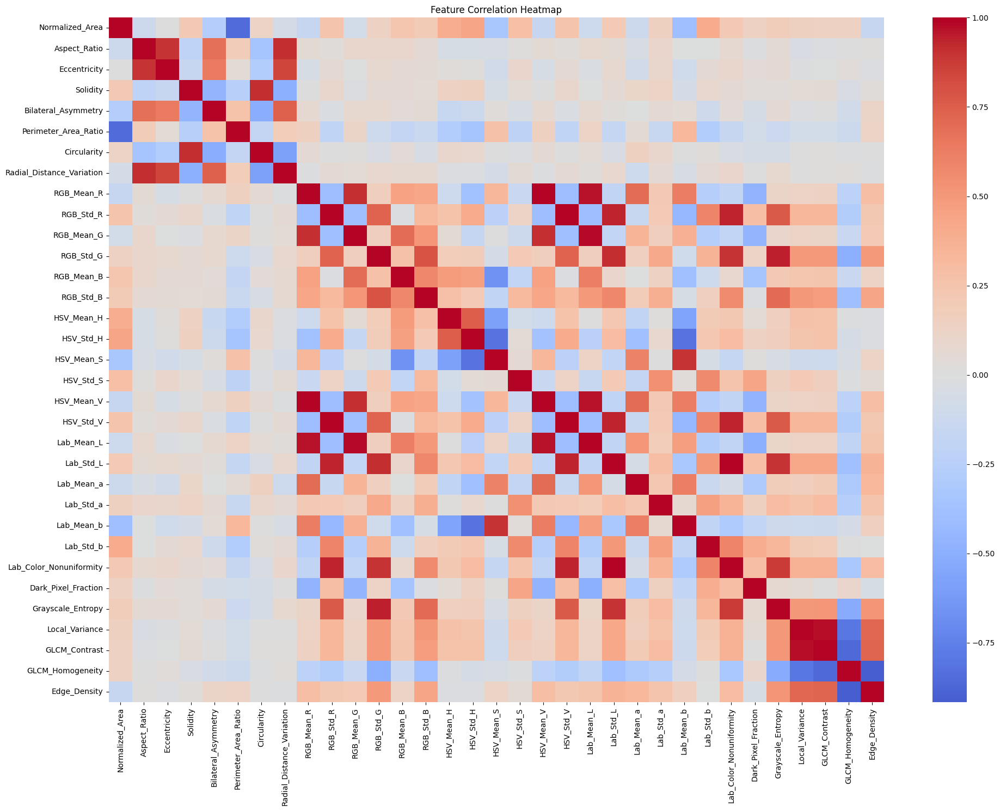

In [ ]:

correlation = master_df[feature_columns].corr()

plt.figure(figsize=(20, 15))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [ ]:

class_statistics = master_df.groupby('Class')[
    feature_columns
].agg(['mean', 'std'])

print(class_statistics.T)


Class                  Atypical Nevus  Common Nevus  Melanoma
Normalized_Area  mean        0.272315      0.217460  0.632673
                 std         0.172239      0.140866  0.230731
Aspect_Ratio     mean        1.390458      1.333310  1.312272
                 std         0.269075      0.286162  0.142392
Eccentricity     mean        0.641997      0.596231  0.625335
...                               ...           ...       ...
GLCM_Contrast    std         0.185197      0.188568  0.239543
GLCM_Homogeneity mean        0.819940      0.816070  0.830932
                 std         0.036553      0.036031  0.035564
Edge_Density     mean        0.101293      0.113643  0.078742
                 std         0.060361      0.068772  0.054981

[66 rows x 3 columns]


In [ ]:

class_statistics.to_csv(
    '/content/PH2_Class_Feature_Statistics.csv'
)

print("Feature statistics saved!")


Feature statistics saved!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

feature_columns = [
    col for col in master_df.columns
    if col not in ['Image_ID', 'Class']
]

sns.set_theme(style="whitegrid")

print("Number of features:", len(feature_columns))
print("Number of images:", len(master_df))


Number of features: 33
Number of images: 200


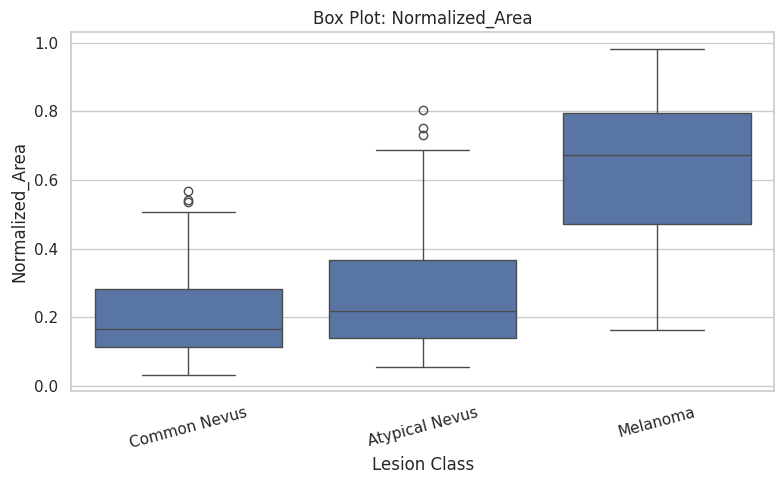

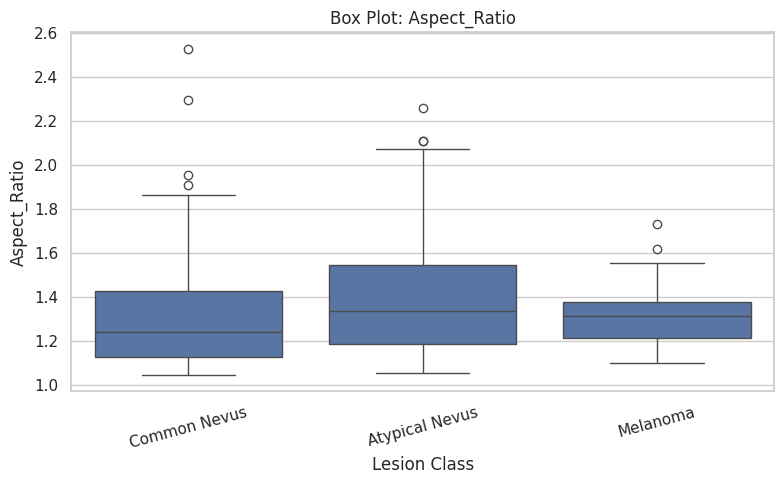

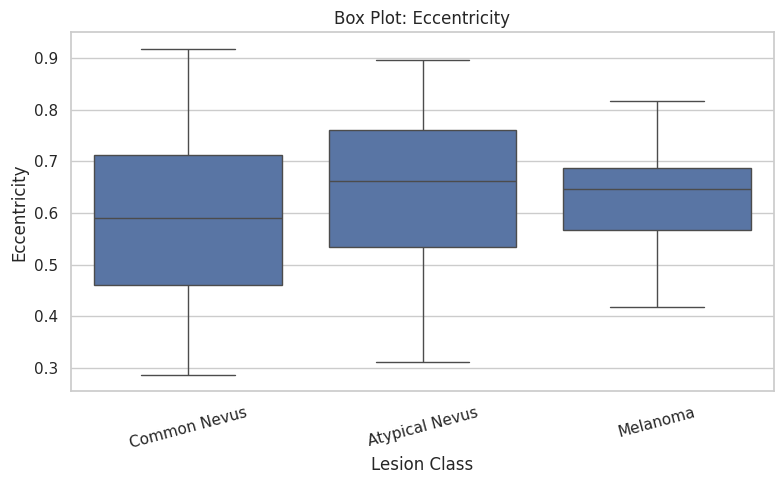

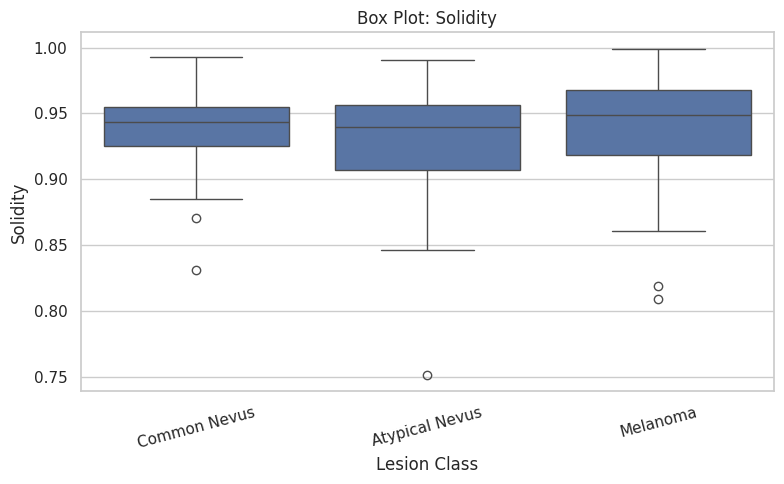

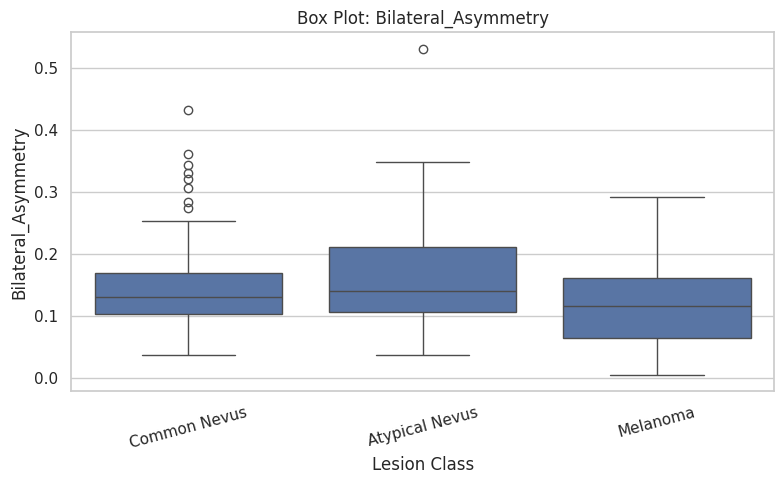

...

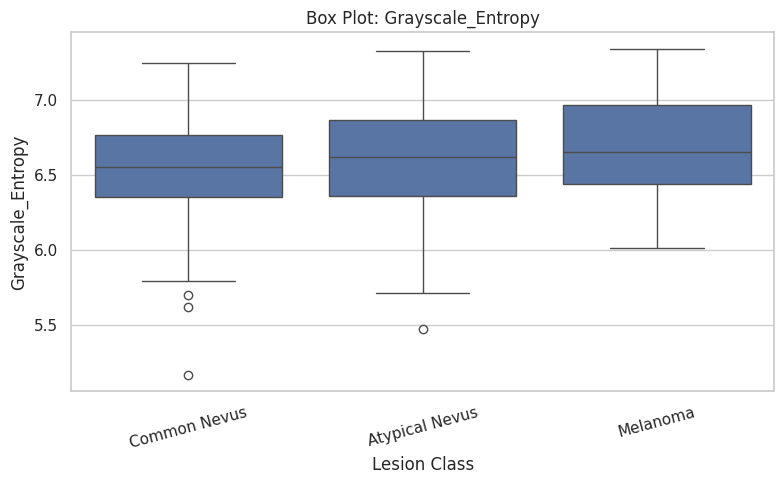

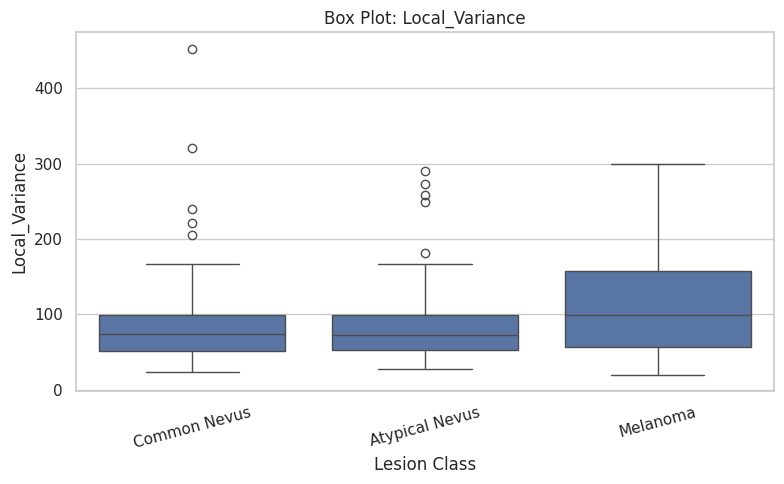

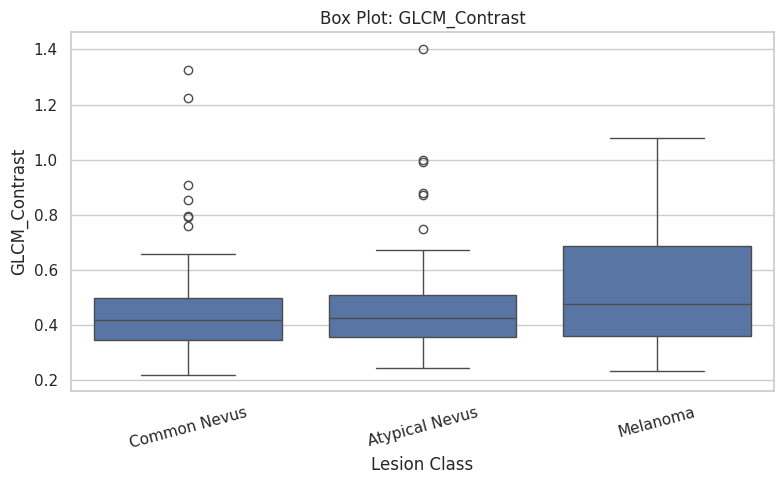

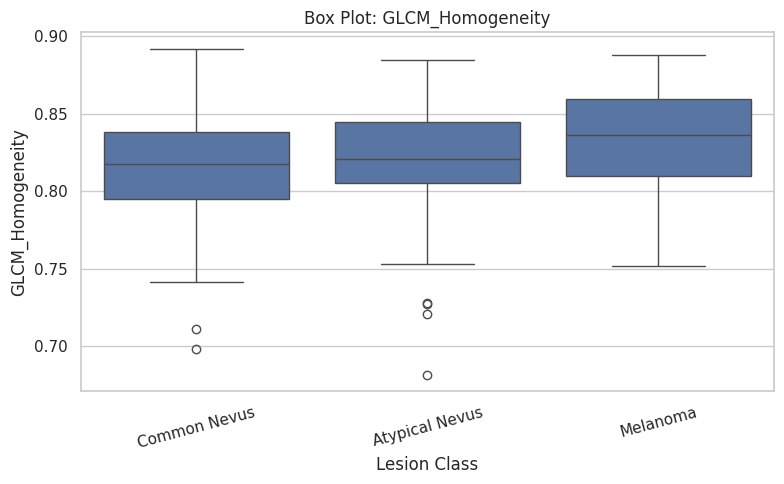

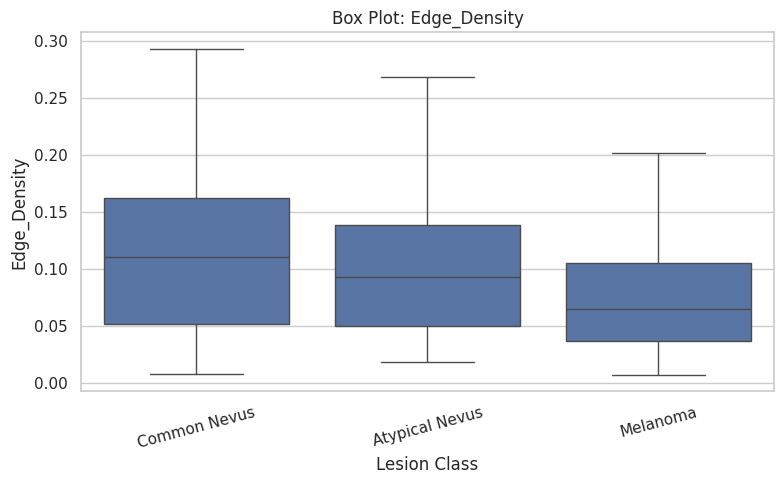

In [ ]:

for feature in feature_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=master_df,
        x='Class',
        y=feature,
        order=['Common Nevus', 'Atypical Nevus', 'Melanoma']
    )

    plt.title(f'Box Plot: {feature}')
    plt.xlabel('Lesion Class')
    plt.ylabel(feature)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


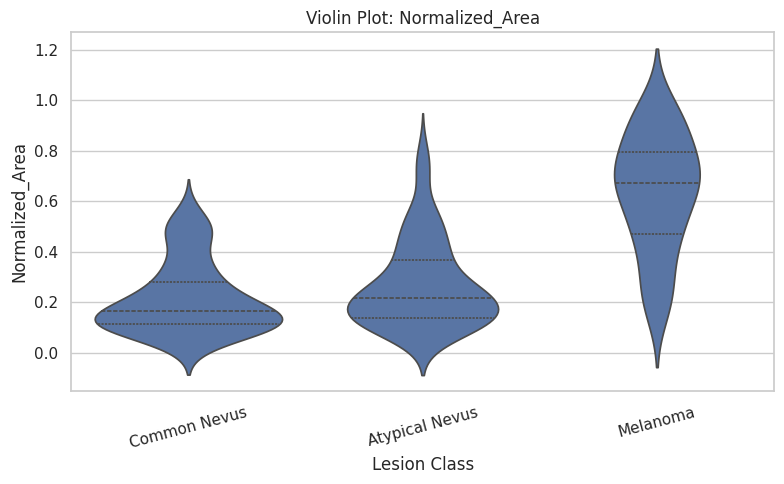

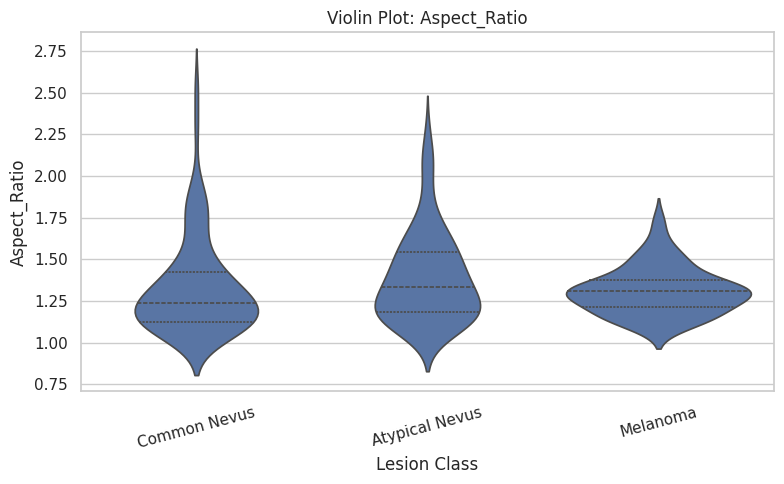

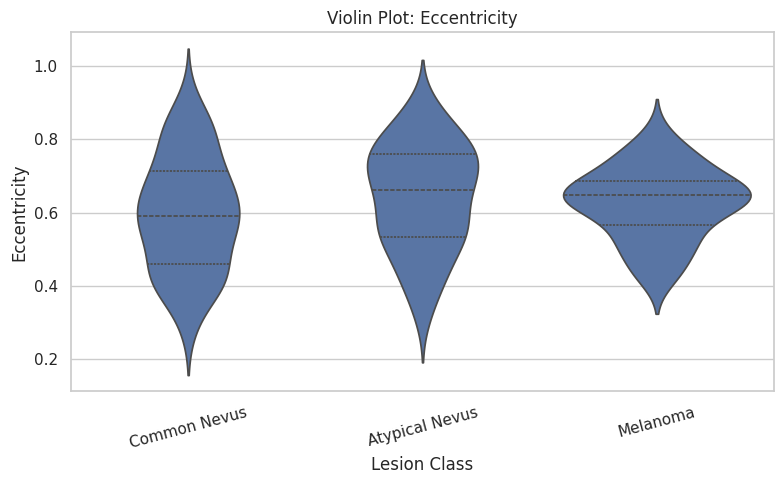

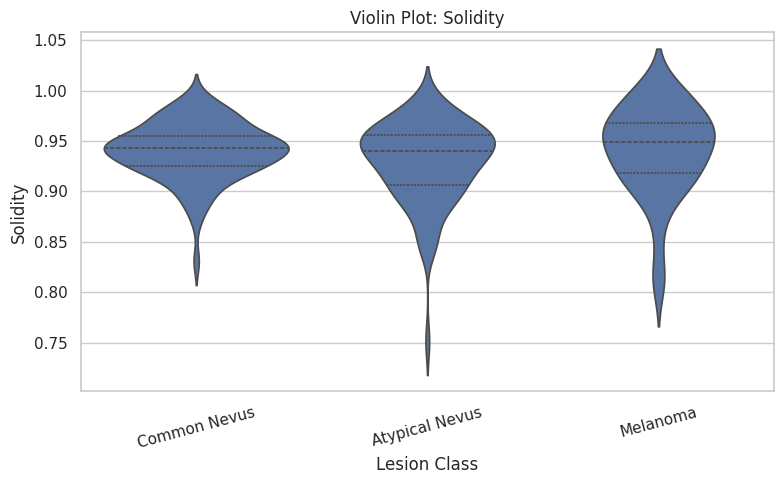

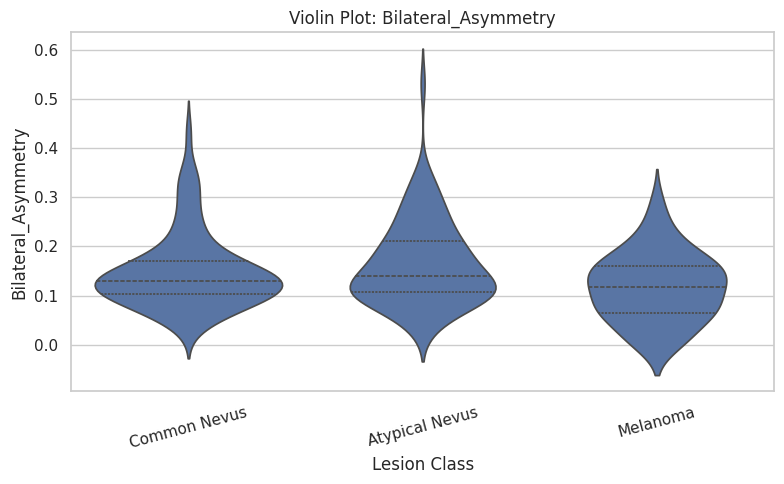

...

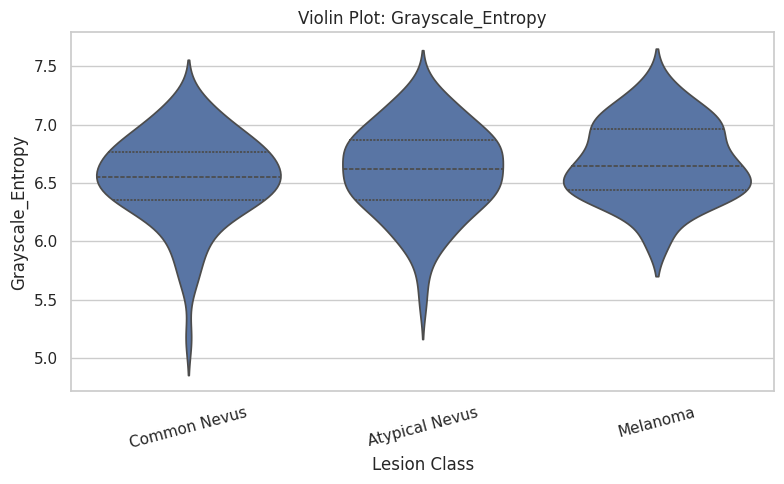

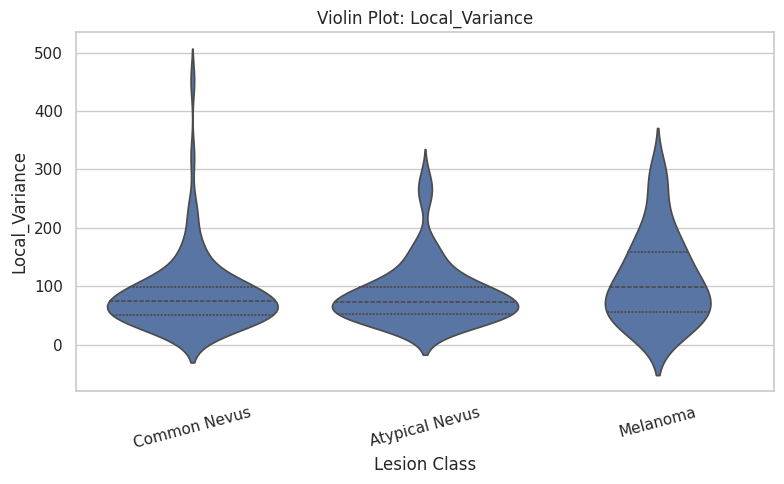

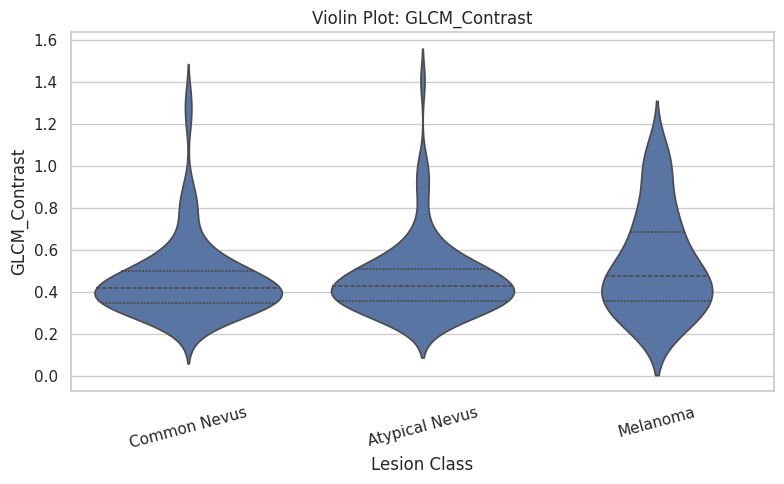

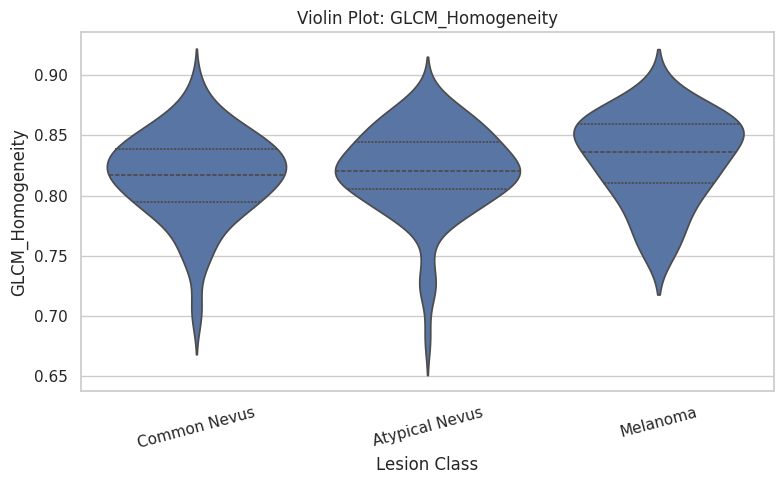

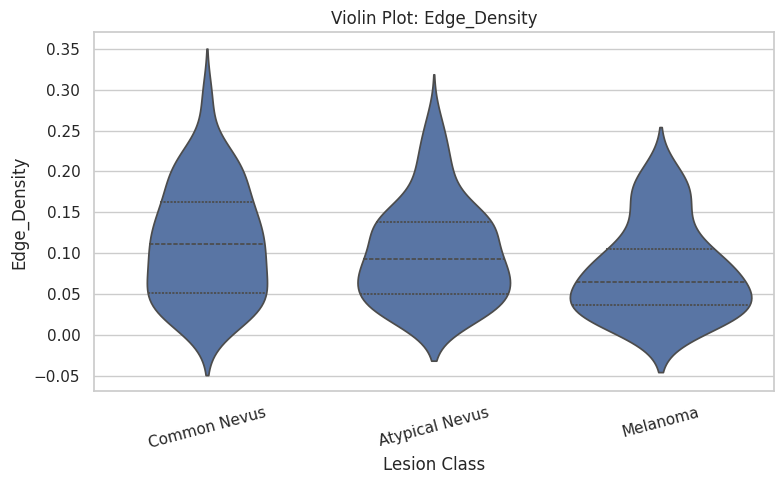

In [ ]:

for feature in feature_columns:

    plt.figure(figsize=(8, 5))

    sns.violinplot(
        data=master_df,
        x='Class',
        y=feature,
        order=['Common Nevus', 'Atypical Nevus', 'Melanoma'],
        inner='quartile'
    )

    plt.title(f'Violin Plot: {feature}')
    plt.xlabel('Lesion Class')
    plt.ylabel(feature)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


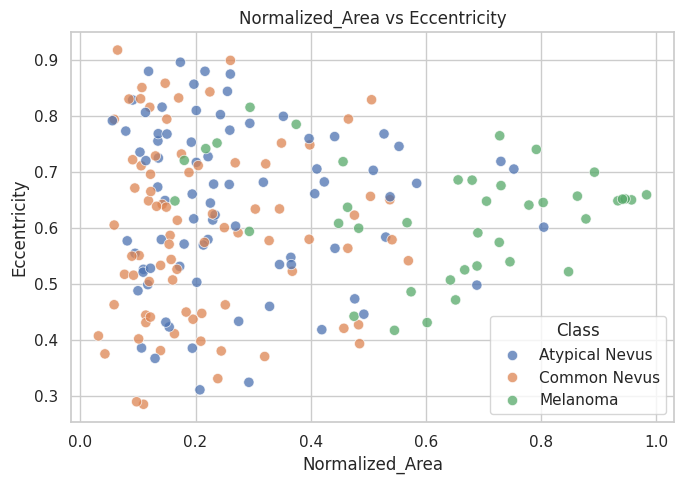

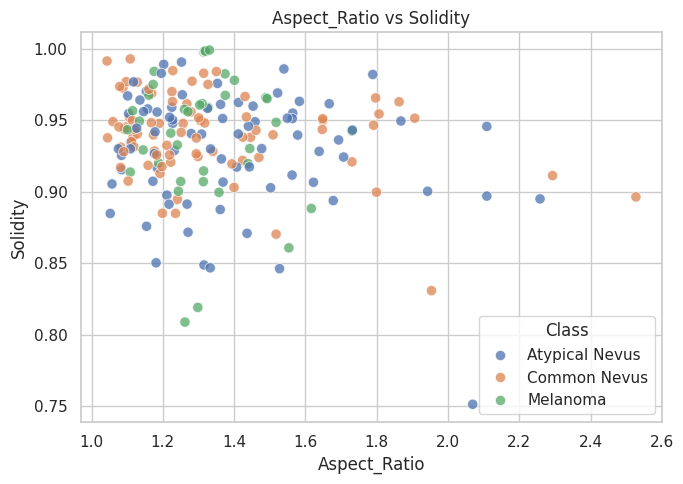

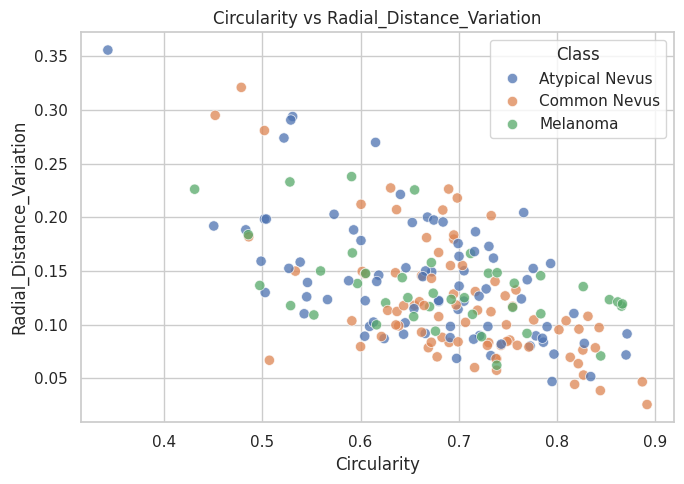

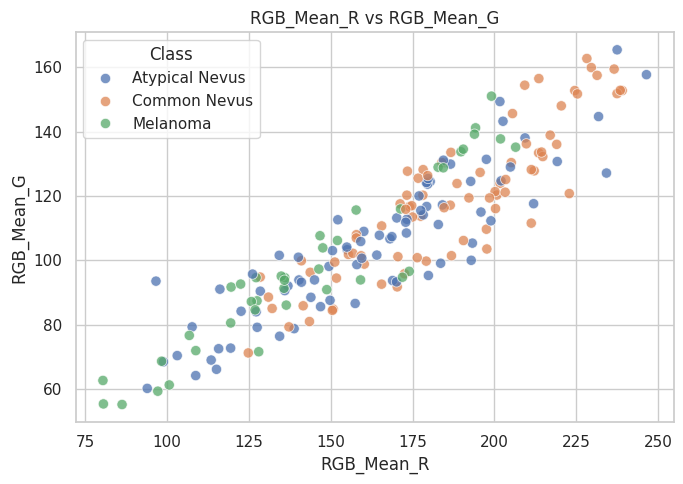

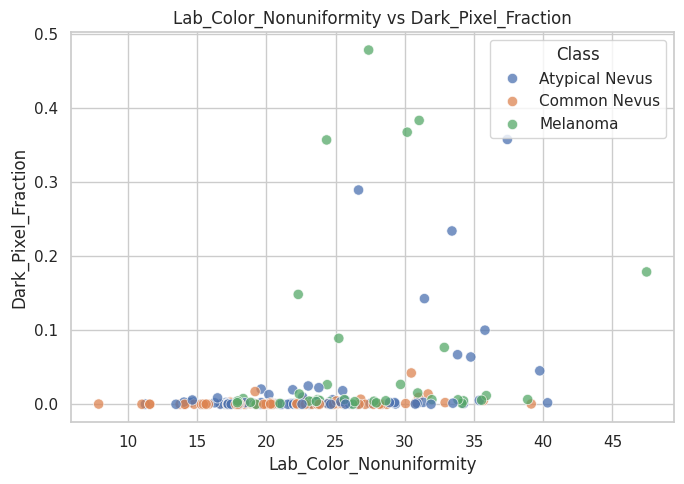

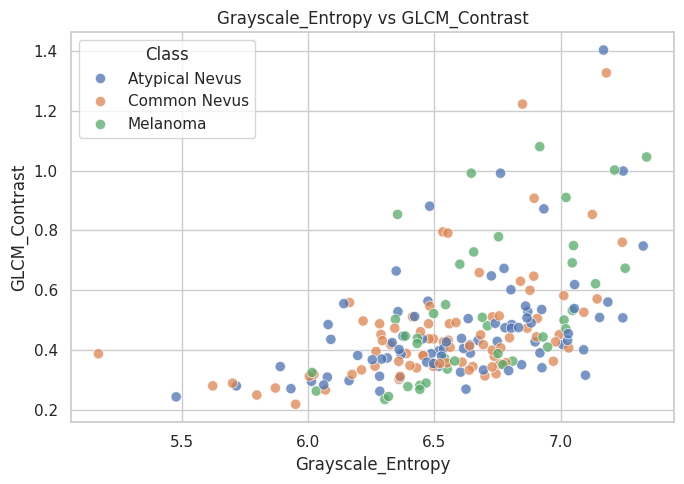

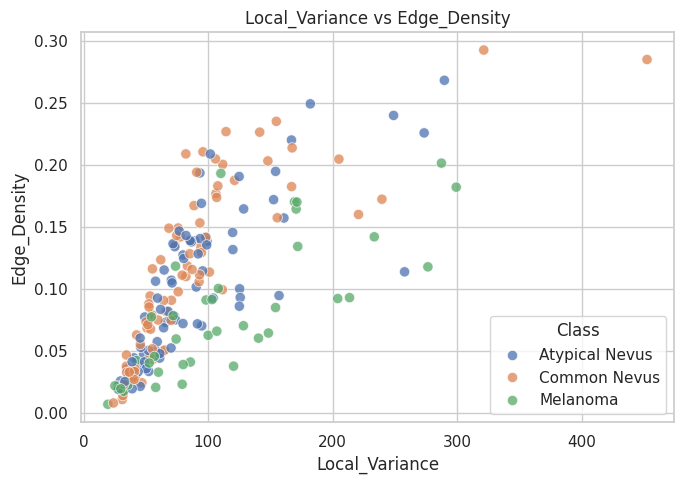

In [ ]:

scatter_pairs = [
    ('Normalized_Area', 'Eccentricity'),
    ('Aspect_Ratio', 'Solidity'),
    ('Circularity', 'Radial_Distance_Variation'),
    ('RGB_Mean_R', 'RGB_Mean_G'),
    ('Lab_Color_Nonuniformity', 'Dark_Pixel_Fraction'),
    ('Grayscale_Entropy', 'GLCM_Contrast'),
    ('Local_Variance', 'Edge_Density')
]

for x_feature, y_feature in scatter_pairs:

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=master_df,
        x=x_feature,
        y=y_feature,
        hue='Class',
        alpha=0.75,
        s=55
    )

    plt.title(f'{x_feature} vs {y_feature}')
    plt.tight_layout()
    plt.show()


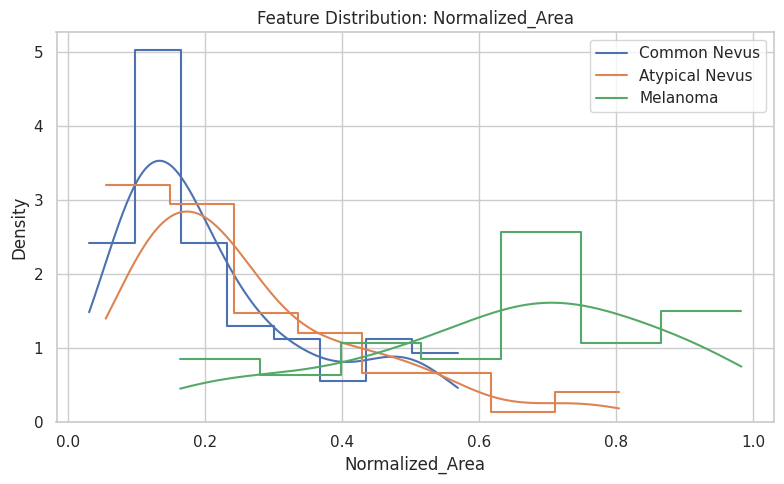

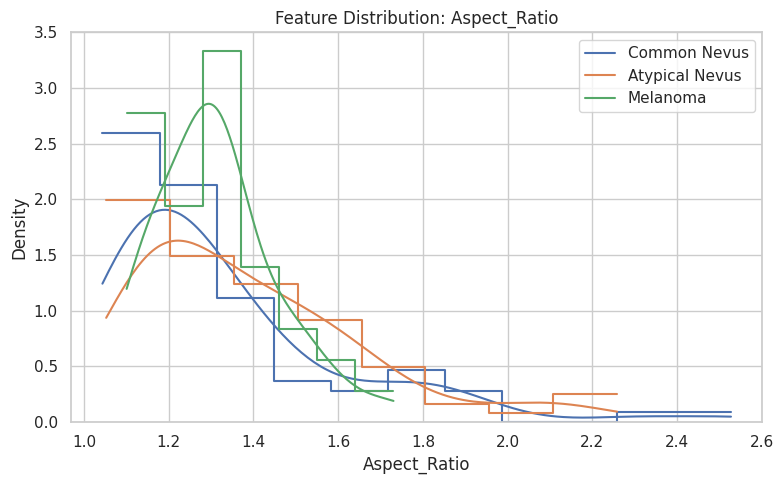

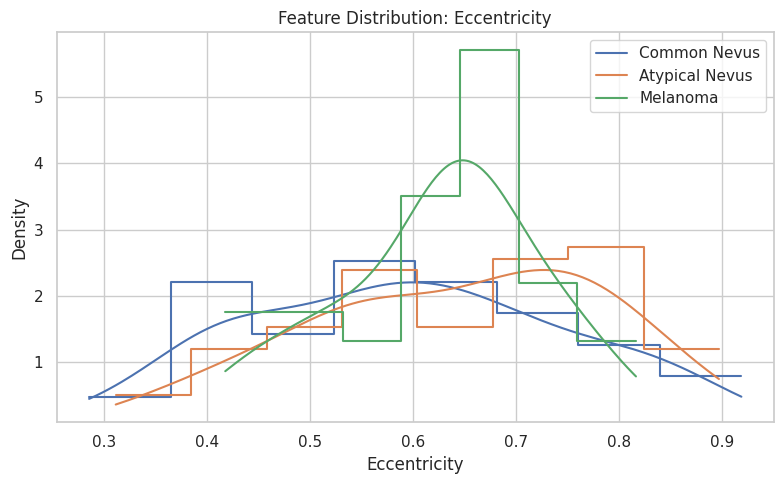

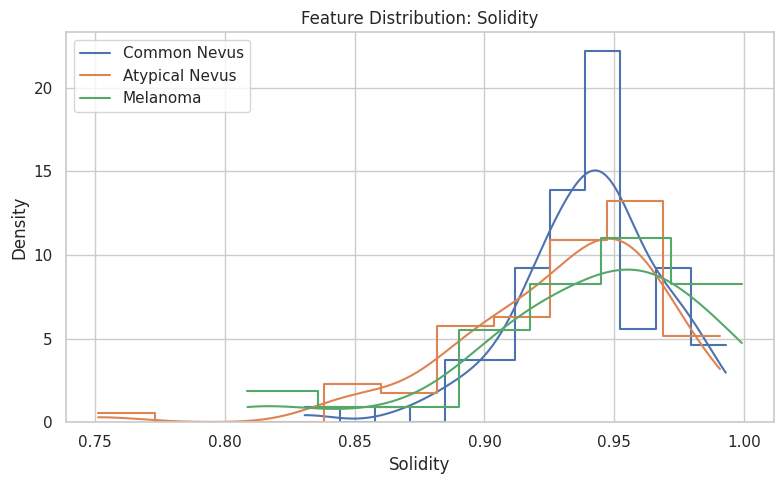

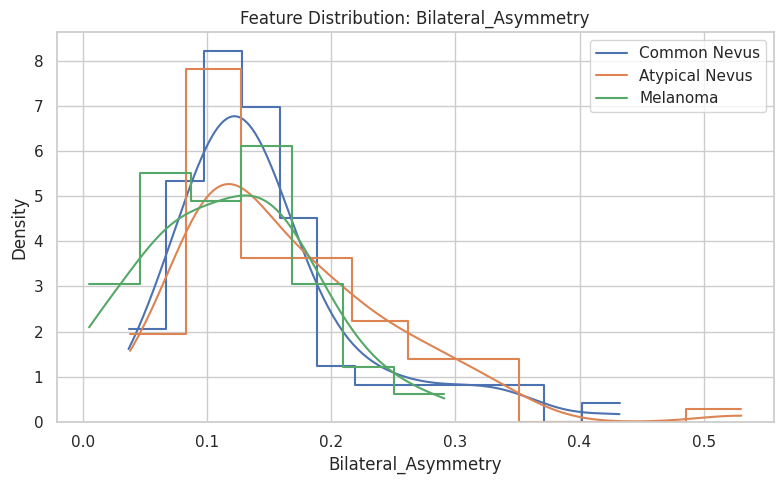

...

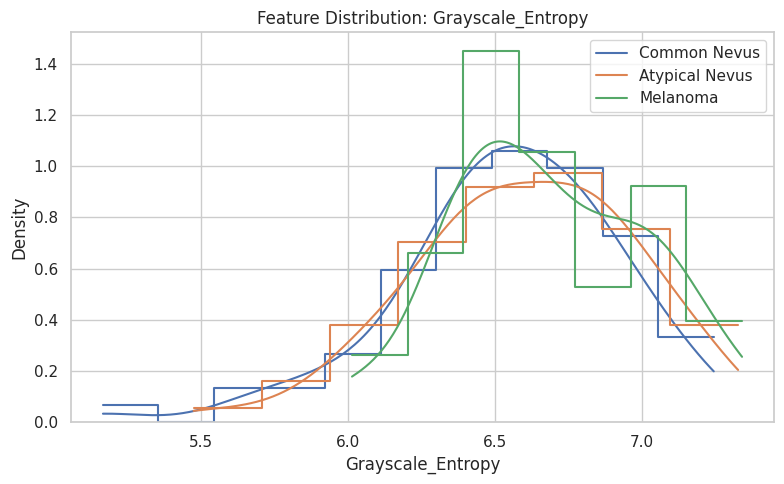

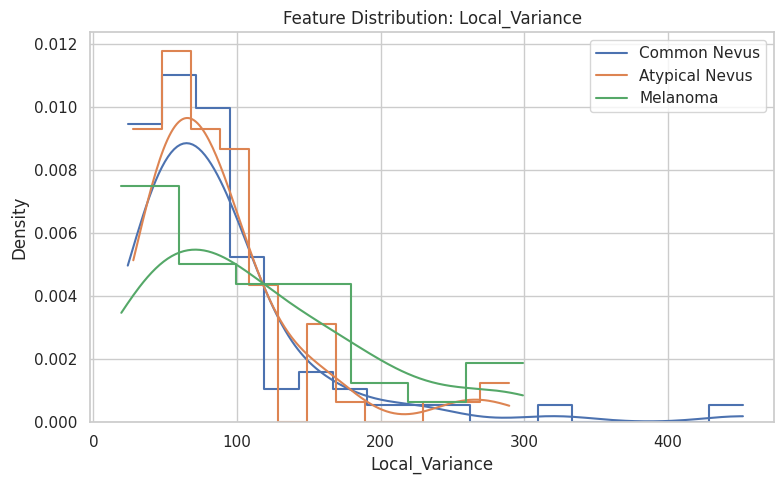

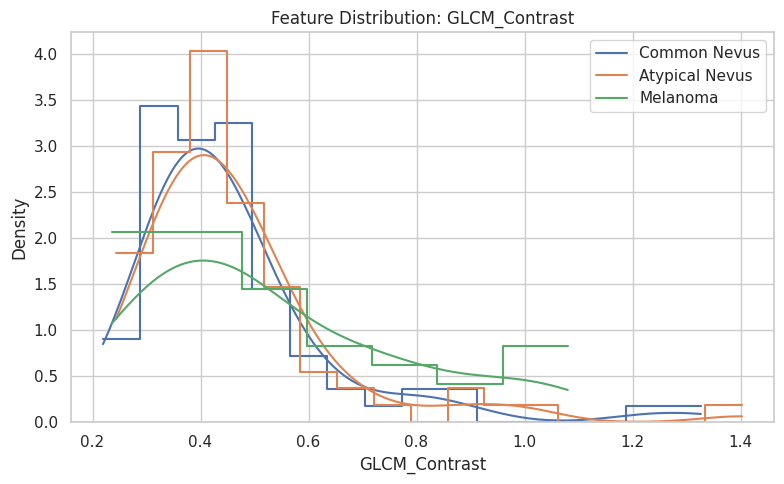

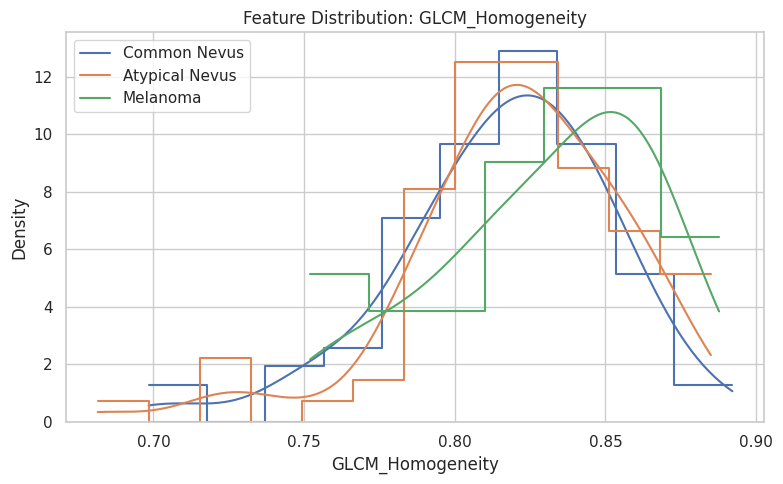

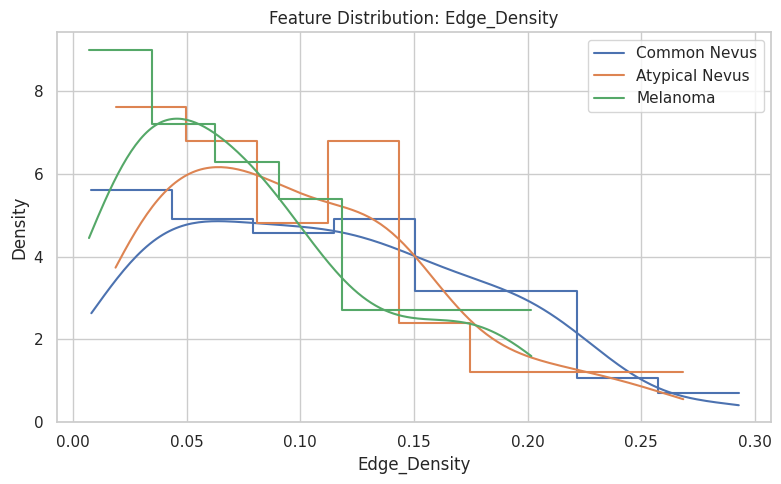

In [ ]:

for feature in feature_columns:

    plt.figure(figsize=(8, 5))

    for class_name in [
        'Common Nevus',
        'Atypical Nevus',
        'Melanoma'
    ]:

        values = master_df.loc[
            master_df['Class'] == class_name,
            feature
        ]

        sns.histplot(
            values,
            label=class_name,
            kde=True,
            stat='density',
            element='step',
            fill=False
        )

    plt.title(f'Feature Distribution: {feature}')
    plt.xlabel(feature)
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.show()


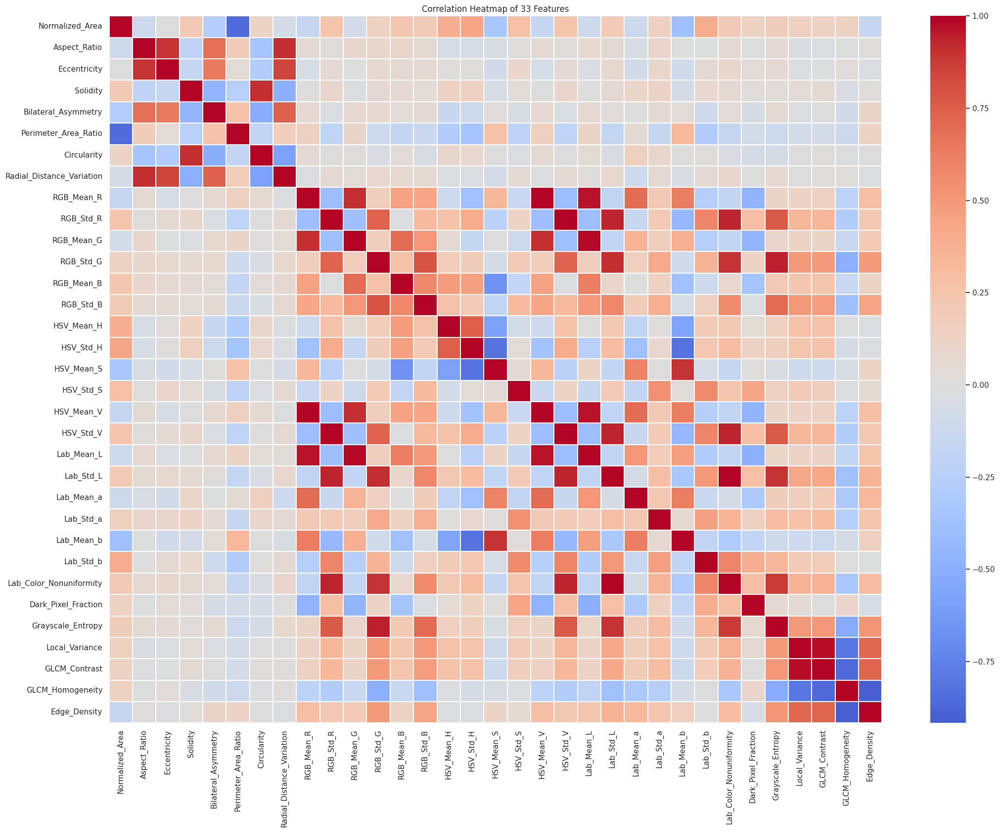

In [ ]:

correlation = master_df[feature_columns].corr(method='pearson')

plt.figure(figsize=(22, 17))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.2
)

plt.title('Correlation Heatmap of 33 Features')
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.feature_selection import f_classif
from sklearn.preprocessing import LabelEncoder

X = master_df[feature_columns].copy()

y = LabelEncoder().fit_transform(
    master_df['Class']
)

f_scores, p_values = f_classif(X, y)

feature_ranking = pd.DataFrame({
    'Feature': feature_columns,
    'ANOVA_F_Score': f_scores,
    'P_Value': p_values
})

feature_ranking = feature_ranking.sort_values(
    by='ANOVA_F_Score',
    ascending=False
)

print("Top 10 potentially useful features:")
print(feature_ranking.head(10).to_string(index=False))

print("\nBottom 10 features:")
print(feature_ranking.tail(10).to_string(index=False))

feature_ranking.to_csv(
    '/content/PH2_Feature_Ranking.csv',
    index=False
)


Top 10 potentially useful features:
             Feature  ANOVA_F_Score      P_Value
     Normalized_Area      81.143521 1.967570e-26
           HSV_Std_H      50.689035 1.739336e-18
          Lab_Mean_b      46.603080 2.681147e-17
Perimeter_Area_Ratio      33.657532 2.666334e-13
          HSV_Mean_H      30.965814 2.023908e-12
           Lab_Std_b      26.431797 6.779217e-11
          HSV_Mean_S      26.205042 8.107623e-11
          RGB_Mean_R      23.386233 7.707883e-10
          HSV_Mean_V      23.347715 7.951628e-10
           RGB_Std_R      17.605512 9.235580e-08

Bottom 10 features:
          Feature  ANOVA_F_Score  P_Value
   Local_Variance       2.386155 0.094637
      Circularity       2.362934 0.096807
 GLCM_Homogeneity       2.275237 0.105467
Grayscale_Entropy       2.155066 0.118620
     Eccentricity       2.118182 0.122981
    GLCM_Contrast       2.066043 0.129422
         Solidity       2.064489 0.129620
     Aspect_Ratio       1.589074 0.206720
        RGB_Std_G       1.

In [ ]:

correlation.to_csv(
    '/content/PH2_Feature_Correlation.csv'
)

feature_ranking.to_csv(
    '/content/PH2_Feature_Ranking.csv',
    index=False
)

print("Analysis files saved successfully!")


Analysis files saved successfully!


In [ ]:
import numpy as np
import pandas as pd

feature_columns = [
    col for col in master_df.columns
    if col not in ['Image_ID', 'Class']
]

correlation = master_df[feature_columns].corr(method='pearson')

# Get only the upper triangle to avoid duplicate pairs
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

correlation_pairs = (
    upper_triangle.stack()
    .reset_index()
)

correlation_pairs.columns = [
    'Feature_1', 'Feature_2', 'Correlation'
]

# Keep strongly correlated pairs
strong_pairs = correlation_pairs[
    correlation_pairs['Correlation'].abs() >= 0.85
].copy()

strong_pairs['Absolute_Correlation'] = (
    strong_pairs['Correlation'].abs()
)

strong_pairs = strong_pairs.sort_values(
    'Absolute_Correlation',
    ascending=False
)

print("Strongly correlated feature pairs:")
display(strong_pairs)

print("Total strongly correlated pairs:",
      len(strong_pairs))

strong_pairs.to_csv(
    '/content/PH2_Strong_Correlations.csv',
    index=False
)

Strongly correlated feature pairs:


,Feature_1,Feature_2,Correlation,Absolute_Correlation
237,RGB_Mean_R,HSV_Mean_V,0.999990,0.999990
261,RGB_Std_R,HSV_Std_V,0.999974,0.999974
466,Lab_Std_L,Lab_Color_Nonuniformity,0.985812,0.985812
284,RGB_Mean_G,Lab_Mean_L,0.983914,0.983914
522,Local_Variance,GLCM_Contrast,0.973436,0.973436
424,HSV_Mean_V,Lab_Mean_L,0.967074,0.967074
239,RGB_Mean_R,Lab_Mean_L,0.966733,0.966733
313,RGB_Std_G,Grayscale_Entropy,0.946537,0.946537
438,HSV_Std_V,Lab_Std_L,0.936024,0.936024
263,RGB_Std_R,Lab_Std_L,0.935865,0.935865


Total strongly correlated pairs: 25


In [ ]:
# Sort features by ANOVA F-score
ranked_features = feature_ranking.sort_values(
    'ANOVA_F_Score',
    ascending=False
)['Feature'].tolist()

selected_features = []
removed_features = []

threshold = 0.90

for feature in ranked_features:

    redundant_with = None

    for selected in selected_features:

        corr_value = correlation.loc[feature, selected]

        if abs(corr_value) >= threshold:
            redundant_with = selected
            break

    if redundant_with is None:
        selected_features.append(feature)

    else:
        removed_features.append({
            'Removed_Feature': feature,
            'Kept_Feature': redundant_with,
            'Correlation': correlation.loc[
                feature, redundant_with
            ]
        })

print("Original number of features:", len(feature_columns))
print("Refined number of features:", len(selected_features))
print("Removed number of features:", len(removed_features))

print("\nSelected features:")
for feature in selected_features:
    print(feature)

print("\nRemoved features:")
display(pd.DataFrame(removed_features))

Original number of features: 33
Refined number of features: 21
Removed number of features: 12

Selected features:
Normalized_Area
HSV_Std_H
Lab_Mean_b
Perimeter_Area_Ratio
HSV_Mean_H
Lab_Std_b
RGB_Mean_R
RGB_Std_R
Lab_Mean_a
HSV_Std_S
Dark_Pixel_Fraction
Bilateral_Asymmetry
Edge_Density
Radial_Distance_Variation
RGB_Mean_B
Lab_Std_a
Local_Variance
Circularity
Grayscale_Entropy
Eccentricity
RGB_Std_B

Removed features:


,Removed_Feature,Kept_Feature,Correlation
0,HSV_Mean_S,Lab_Mean_b,0.900221
1,HSV_Mean_V,RGB_Mean_R,0.999990
2,HSV_Std_V,RGB_Std_R,0.999974
3,Lab_Mean_L,RGB_Mean_R,0.966733
4,RGB_Mean_G,RGB_Mean_R,0.908418
5,Lab_Color_Nonuniformity,RGB_Std_R,0.932668
6,Lab_Std_L,RGB_Std_R,0.935865
7,GLCM_Homogeneity,Edge_Density,-0.916747
8,GLCM_Contrast,Local_Variance,0.973436
9,Solidity,Circularity,0.912859


In [ ]:
refined_df = master_df[
    ['Image_ID', 'Class'] + selected_features
].copy()

refined_df.to_csv(
    '/content/PH2_Refined_Features.csv',
    index=False
)

print("Refined dataset shape:", refined_df.shape)

Refined dataset shape: (200, 23)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np

# Define feature groups
shape_features = [
    'Normalized_Area',
    'Aspect_Ratio',
    'Eccentricity',
    'Solidity',
    'Bilateral_Asymmetry'
]

border_features = [
    'Perimeter_Area_Ratio',
    'Circularity',
    'Radial_Distance_Variation'
]

color_features = [
    col for col in master_df.columns
    if col.startswith(('RGB_', 'HSV_', 'Lab_'))
    or col == 'Dark_Pixel_Fraction'
]

texture_features = [
    'Grayscale_Entropy',
    'Local_Variance',
    'GLCM_Contrast',
    'GLCM_Homogeneity',
    'Edge_Density'
]

# Combined original and refined sets
all_features = feature_columns
refined_features = selected_features

# Define experiments
experiments = {
    'Shape Only': shape_features,
    'Color Only': color_features,
    'Texture Only': texture_features,
    'Initial Combined (33)': all_features,
    'Refined Combined (21)': refined_features
}

X_all = master_df
y = master_df['Class']

class_order = [
    'Common Nevus',
    'Atypical Nevus',
    'Melanoma'
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
predictions = {}

for experiment_name, features in experiments.items():

    X = X_all[features]

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    )

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    predictions[experiment_name] = y_pred

    results.append({
        'Experiment': experiment_name,
        'Number_of_Features': len(features),
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(
            y, y_pred, average='macro'
        ),
        'Recall': recall_score(
            y, y_pred, average='macro'
        ),
        'F1_Score': f1_score(
            y, y_pred, average='macro'
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

results_df.to_csv(
    '/content/PH2_Classification_Comparison.csv',
    index=False
)

,Experiment,Number_of_Features,Accuracy,Precision,Recall,F1_Score
0,Shape Only,5,0.510,0.5356,0.5333,0.5342
1,Color Only,20,0.555,0.5844,0.5667,0.5744
2,Texture Only,5,0.370,0.3924,0.3750,0.3822
3,Initial Combined (33),33,0.590,0.6274,0.6083,0.6159
4,Refined Combined (21),21,0.590,0.6340,0.6125,0.6217


In [ ]:
experiments['Border Only'] = border_features

In [ ]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced'
)

border_pred = cross_val_predict(
    model,
    master_df[border_features],
    y,
    cv=cv
)

print("Border Only Results")
print("Accuracy:", accuracy_score(y, border_pred))
print("Precision:", precision_score(
    y, border_pred, average='macro'
))
print("Recall:", recall_score(
    y, border_pred, average='macro'
))
print("F1-score:", f1_score(
    y, border_pred, average='macro'
))

Border Only Results
Accuracy: 0.58
Precision: 0.6019256145838424
Recall: 0.5916666666666667
F1-score: 0.5963308052585549



 Initial Combined (33)


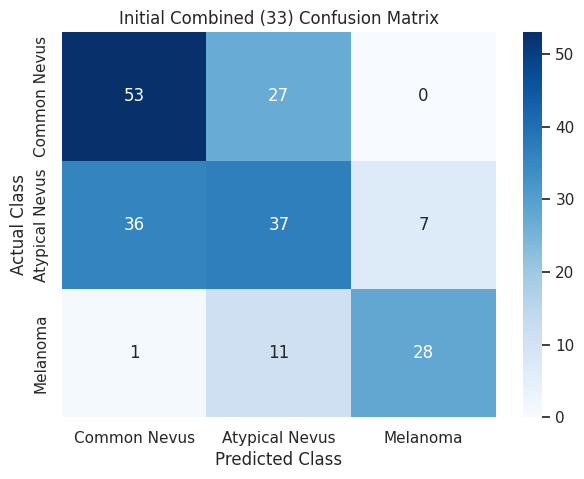

                precision    recall  f1-score   support

  Common Nevus       0.59      0.66      0.62        80
Atypical Nevus       0.49      0.46      0.48        80
      Melanoma       0.80      0.70      0.75        40

      accuracy                           0.59       200
     macro avg       0.63      0.61      0.62       200
  weighted avg       0.59      0.59      0.59       200


 Refined Combined (21)


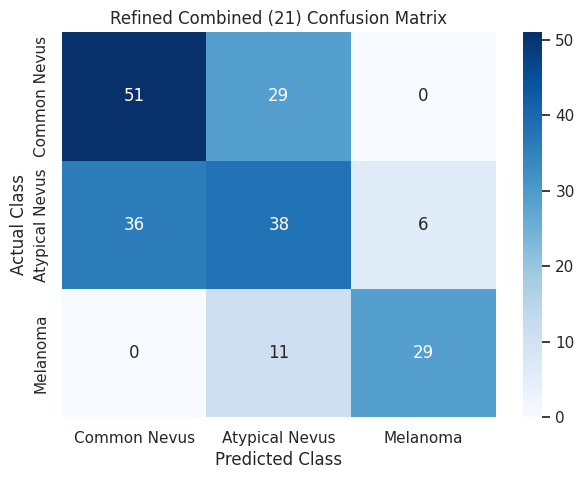

                precision    recall  f1-score   support

  Common Nevus       0.59      0.64      0.61        80
Atypical Nevus       0.49      0.47      0.48        80
      Melanoma       0.83      0.72      0.77        40

      accuracy                           0.59       200
     macro avg       0.63      0.61      0.62       200
  weighted avg       0.60      0.59      0.59       200



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class_order = [
    'Common Nevus',
    'Atypical Nevus',
    'Melanoma'
]

for name in [
    'Initial Combined (33)',
    'Refined Combined (21)'
]:

    print("\n", name)

    y_pred = predictions[name]

    cm = confusion_matrix(
        y,
        y_pred,
        labels=class_order
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_order,
        yticklabels=class_order
    )

    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.title(name + ' Confusion Matrix')
    plt.show()

    print(classification_report(
        y,
        y_pred,
        labels=class_order,
        zero_division=0
    ))

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

X = master_df[selected_features]
y = master_df['Class']

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced'
)

# Get cross-validation predictions and probabilities
predicted = cross_val_predict(
    model, X, y, cv=cv
)

probabilities = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    method='predict_proba'
)

# Match probability columns to class names
classes = model.fit(X, y).classes_

# Create result table
failure_df = pd.DataFrame({
    'Image_ID': master_df['Image_ID'],
    'Actual_Class': y,
    'Predicted_Class': predicted,
    'Confidence': probabilities.max(axis=1),
    'Correct': predicted == y
})

# Show misclassified images
misclassified = failure_df[
    failure_df['Correct'] == False
].sort_values('Confidence', ascending=False)

print("Total misclassified:", len(misclassified))

display(misclassified.head(20))

misclassified.to_csv(
    '/content/PH2_Misclassified_Images.csv',
    index=False
)

Total misclassified: 82


,Image_ID,Actual_Class,Predicted_Class,Confidence,Correct
121,IMD278,Atypical Nevus,Common Nevus,0.836667,False
69,IMD137,Atypical Nevus,Common Nevus,0.820000,False
22,IMD031,Atypical Nevus,Melanoma,0.796667,False
132,IMD339,Atypical Nevus,Common Nevus,0.780000,False
14,IMD020,Common Nevus,Atypical Nevus,0.760000,False
167,IMD398,Atypical Nevus,Melanoma,0.720000,False
75,IMD144,Common Nevus,Atypical Nevus,0.703333,False
1,IMD003,Common Nevus,Atypical Nevus,0.696667,False
123,IMD280,Atypical Nevus,Common Nevus,0.693333,False
32,IMD042,Common Nevus,Atypical Nevus,0.690000,False


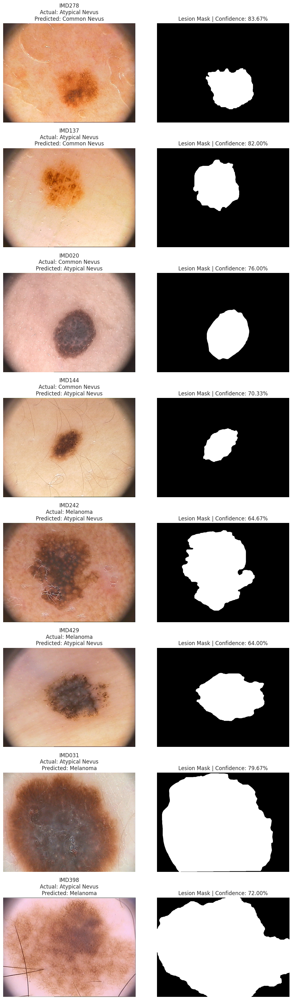

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Select two examples from each important confusion pattern
patterns = [
    ('Atypical Nevus', 'Common Nevus'),
    ('Common Nevus', 'Atypical Nevus'),
    ('Melanoma', 'Atypical Nevus'),
    ('Atypical Nevus', 'Melanoma')
]

selected_cases = []

for actual, predicted_class in patterns:

    cases = misclassified[
        (misclassified['Actual_Class'] == actual) &
        (misclassified['Predicted_Class'] == predicted_class)
    ].head(2)

    selected_cases.extend(cases['Image_ID'].tolist())

# Display images and masks
fig, axes = plt.subplots(
    len(selected_cases), 2,
    figsize=(10, 4 * len(selected_cases))
)

for i, image_id in enumerate(selected_cases):

    image, mask = load_image_and_mask(image_id)

    actual = misclassified.loc[
        misclassified['Image_ID'] == image_id,
        'Actual_Class'
    ].iloc[0]

    predicted_class = misclassified.loc[
        misclassified['Image_ID'] == image_id,
        'Predicted_Class'
    ].iloc[0]

    confidence = misclassified.loc[
        misclassified['Image_ID'] == image_id,
        'Confidence'
    ].iloc[0]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"{image_id}\nActual: {actual}\nPredicted: {predicted_class}"
    )
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask, cmap='gray')
    axes[i, 1].set_title(
        f"Lesion Mask | Confidence: {confidence:.2%}"
    )
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
selected_ids = [
    'IMD278', 'IMD137',
    'IMD020', 'IMD144',
    'IMD242', 'IMD429'
]

selected_data = master_df[
    master_df['Image_ID'].isin(selected_ids)
].copy()

# Compare selected images with class averages
important_features = [
    'Normalized_Area',
    'Perimeter_Area_Ratio',
    'Circularity',
    'Bilateral_Asymmetry',
    'HSV_Mean_H',
    'HSV_Std_H',
    'Lab_Mean_b',
    'RGB_Mean_R',
    'Grayscale_Entropy',
    'Local_Variance',
    'Edge_Density'
]

print("Selected misclassified image features:")
display(
    selected_data[
        ['Image_ID', 'Class'] + important_features
    ].round(4)
)

print("\nClass average feature values:")
display(
    master_df.groupby('Class')[important_features]
    .mean()
    .round(4)
)

Selected misclassified image features:


,Image_ID,Class,Normalized_Area,Perimeter_Area_Ratio,Circularity,Bilateral_Asymmetry,HSV_Mean_H,HSV_Std_H,Lab_Mean_b,RGB_Mean_R,Grayscale_Entropy,Local_Variance,Edge_Density
14,IMD020,Common Nevus,0.1184,0.0170,0.8429,0.1444,43.4260,72.7699,135.3805,128.4519,6.1636,101.044800,0.1138
69,IMD137,Atypical Nevus,0.1297,0.0178,0.6978,0.0744,13.4603,1.3470,179.2914,219.1856,6.6722,79.862900,0.1276
75,IMD144,Common Nevus,0.0588,0.0265,0.6949,0.3055,10.4457,3.5070,154.2792,156.7388,7.0321,73.270302,0.1359
116,IMD242,Melanoma,0.2934,0.0140,0.4975,0.1309,10.1742,17.3727,148.3181,136.4084,6.6003,148.406998,0.0645
121,IMD278,Atypical Nevus,0.1095,0.0200,0.6544,0.1176,11.4501,1.1891,175.1394,211.9672,6.6151,73.229897,0.1342
191,IMD429,Melanoma,0.1804,0.0157,0.6425,0.0754,11.1004,19.2685,145.7890,135.8597,6.7516,71.941200,0.0786



Class average feature values:


,Normalized_Area,Perimeter_Area_Ratio,Circularity,Bilateral_Asymmetry,HSV_Mean_H,HSV_Std_H,Lab_Mean_b,RGB_Mean_R,Grayscale_Entropy,Local_Variance,Edge_Density
Class,,,,,,,,,,,
Atypical Nevus,0.2723,0.0146,0.6651,0.1655,15.8611,15.4348,153.8244,163.1050,6.6012,88.137604,0.1013
Common Nevus,0.2175,0.0161,0.6998,0.1492,12.3207,7.6518,160.5605,185.8616,6.5389,88.346298,0.1136
Melanoma,0.6327,0.0089,0.6806,0.1180,44.0671,46.6945,141.9027,143.8263,6.6850,112.762497,0.0787


In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist
import pandas as pd

# Use the refined 21 features
X = master_df[selected_features]

# Standardize all features
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=selected_features,
    index=master_df.index
)

# Calculate average standardized feature values per class
class_centers = X_scaled.groupby(
    master_df['Class']
).mean()

# Calculate distances for the six selected images
distance_results = []

for image_id in selected_ids:

    idx = master_df.index[
        master_df['Image_ID'] == image_id
    ][0]

    image_vector = X_scaled.loc[[idx]]

    distances = cdist(
        image_vector,
        class_centers,
        metric='euclidean'
    )[0]

    actual_class = master_df.loc[idx, 'Class']

    distance_results.append({
        'Image_ID': image_id,
        'Actual_Class': actual_class,
        'Closest_Class': class_centers.index[
            distances.argmin()
        ],
        'Distance_to_Common': distances[
            class_centers.index.get_loc('Common Nevus')
        ],
        'Distance_to_Atypical': distances[
            class_centers.index.get_loc('Atypical Nevus')
        ],
        'Distance_to_Melanoma': distances[
            class_centers.index.get_loc('Melanoma')
        ]
    })

distance_df = pd.DataFrame(distance_results)

display(distance_df.round(3))

,Image_ID,Actual_Class,Closest_Class,Distance_to_Common,Distance_to_Atypical,Distance_to_Melanoma
0,IMD278,Atypical Nevus,Common Nevus,2.714,3.732,6.258
1,IMD137,Atypical Nevus,Common Nevus,4.303,5.118,6.649
2,IMD020,Common Nevus,Atypical Nevus,4.830,4.434,4.741
3,IMD144,Common Nevus,Atypical Nevus,4.495,4.111,6.215
4,IMD242,Melanoma,Atypical Nevus,3.519,2.602,3.554
5,IMD429,Melanoma,Atypical Nevus,3.587,2.591,3.406


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Original 33 features
feature_columns = [
    col for col in master_df.columns
    if col not in ['Image_ID', 'Class']
]

# Descriptor groups
shape_features = [
    'Normalized_Area',
    'Aspect_Ratio',
    'Eccentricity',
    'Solidity',
    'Bilateral_Asymmetry'
]

border_features = [
    'Perimeter_Area_Ratio',
    'Circularity',
    'Radial_Distance_Variation'
]

color_features = [
    col for col in feature_columns
    if col.startswith(('RGB_', 'HSV_', 'Lab_'))
    or col == 'Dark_Pixel_Fraction'
]

texture_features = [
    'Grayscale_Entropy',
    'Local_Variance',
    'GLCM_Contrast',
    'GLCM_Homogeneity',
    'Edge_Density'
]

X = master_df[feature_columns].reset_index(drop=True)
y = master_df['Class'].reset_index(drop=True)

image_ids = master_df['Image_ID'].reset_index(drop=True)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Total images:", len(X))
print("Original features:", len(feature_columns))
print("Shape features:", len(shape_features))
print("Border features:", len(border_features))
print("Color features:", len(color_features))
print("Texture features:", len(texture_features))

Total images: 200
Original features: 33
Shape features: 5
Border features: 3
Color features: 20
Texture features: 5


In [ ]:
def select_features_from_training_data(
    X_train,
    y_train,
    correlation_threshold=0.90
):

    # Calculate ANOVA scores using training data only
    f_scores, p_values = f_classif(X_train, y_train)

    ranking = pd.DataFrame({
        'Feature': X_train.columns,
        'F_Score': f_scores
    })

    ranking = ranking.sort_values(
        'F_Score',
        ascending=False
    )

    # Calculate correlations using training data only
    corr = X_train.corr(method='pearson')

    selected = []

    for feature in ranking['Feature']:

        redundant = False

        for existing in selected:

            if abs(corr.loc[feature, existing]) >= correlation_threshold:
                redundant = True
                break

        if not redundant:
            selected.append(feature)

    return selected

In [ ]:
experiments = {
    'Shape Only': shape_features,
    'Border Only': border_features,
    'Color Only': color_features,
    'Texture Only': texture_features,
    'Initial Combined (33)': feature_columns
}

class_order = [
    'Common Nevus',
    'Atypical Nevus',
    'Melanoma'
]

all_predictions = {}
all_probabilities = {}
selected_features_by_fold = {}

results = []

for experiment_name, features in experiments.items():

    predictions = np.empty(len(y), dtype=object)
    probabilities = np.zeros((len(y), 3))

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):

        X_train = X.iloc[train_idx][features]
        X_test = X.iloc[test_idx][features]

        y_train = y.iloc[train_idx]

        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight='balanced'
        )

        model.fit(X_train, y_train)

        predictions[test_idx] = model.predict(X_test)

        fold_probabilities = model.predict_proba(X_test)

        for j, class_name in enumerate(model.classes_):
            probabilities[test_idx, class_order.index(class_name)] = (
                fold_probabilities[:, j]
            )

    all_predictions[experiment_name] = predictions
    all_probabilities[experiment_name] = probabilities

    results.append({
        'Experiment': experiment_name,
        'Number_of_Features': len(features),
        'Accuracy': accuracy_score(y, predictions),
        'Precision': precision_score(
            y, predictions,
            labels=class_order,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y, predictions,
            labels=class_order,
            average='macro',
            zero_division=0
        ),
        'F1_Score': f1_score(
            y, predictions,
            labels=class_order,
            average='macro',
            zero_division=0
        )
    })

# Leakage-safe refined combined experiment
refined_predictions = np.empty(len(y), dtype=object)
refined_probabilities = np.zeros((len(y), 3))

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]

    # Feature selection happens inside this training fold
    selected = select_features_from_training_data(
        X_train,
        y_train,
        correlation_threshold=0.90
    )

    selected_features_by_fold[fold + 1] = selected

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    )

    model.fit(X_train[selected], y_train)

    refined_predictions[test_idx] = model.predict(
        X_test[selected]
    )

    fold_probabilities = model.predict_proba(
        X_test[selected]
    )

    for j, class_name in enumerate(model.classes_):
        refined_probabilities[
            test_idx, class_order.index(class_name)
        ] = fold_probabilities[:, j]

all_predictions['Refined Combined (Nested)'] = refined_predictions
all_probabilities['Refined Combined (Nested)'] = refined_probabilities

# Add refined results
results.append({
    'Experiment': 'Refined Combined (Nested)',
    'Number_of_Features': round(
        np.mean([
            len(v) for v in selected_features_by_fold.values()
        ]), 1
    ),
    'Accuracy': accuracy_score(y, refined_predictions),
    'Precision': precision_score(
        y, refined_predictions,
        labels=class_order,
        average='macro',
        zero_division=0
    ),
    'Recall': recall_score(
        y, refined_predictions,
        labels=class_order,
        average='macro',
        zero_division=0
    ),
    'F1_Score': f1_score(
        y, refined_predictions,
        labels=class_order,
        average='macro',
        zero_division=0
    )
})

final_results = pd.DataFrame(results)

display(final_results.round(4))

final_results.to_csv(
    '/content/PH2_Final_Classification_Results.csv',
    index=False
)

,Experiment,Number_of_Features,Accuracy,Precision,Recall,F1_Score
0,Shape Only,5.0,0.510,0.5356,0.5333,0.5342
1,Border Only,3.0,0.580,0.6019,0.5917,0.5963
2,Color Only,20.0,0.555,0.5844,0.5667,0.5744
3,Texture Only,5.0,0.370,0.3924,0.3750,0.3822
4,Initial Combined (33),33.0,0.590,0.6274,0.6083,0.6159
5,Refined Combined (Nested),21.6,0.605,0.6547,0.6167,0.6323


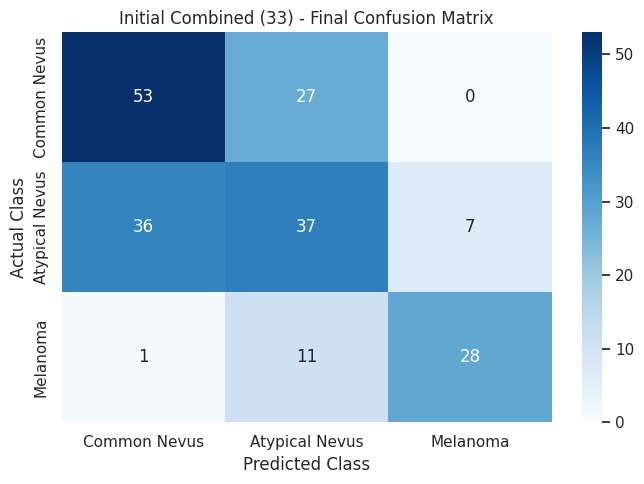


 Initial Combined (33)
                precision    recall  f1-score   support

  Common Nevus       0.59      0.66      0.62        80
Atypical Nevus       0.49      0.46      0.48        80
      Melanoma       0.80      0.70      0.75        40

      accuracy                           0.59       200
     macro avg       0.63      0.61      0.62       200
  weighted avg       0.59      0.59      0.59       200



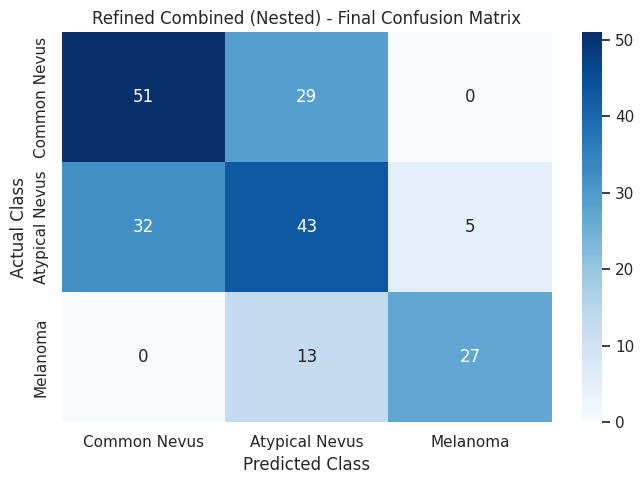


 Refined Combined (Nested)
                precision    recall  f1-score   support

  Common Nevus       0.61      0.64      0.63        80
Atypical Nevus       0.51      0.54      0.52        80
      Melanoma       0.84      0.68      0.75        40

      accuracy                           0.60       200
     macro avg       0.65      0.62      0.63       200
  weighted avg       0.62      0.60      0.61       200



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for name in [
    'Initial Combined (33)',
    'Refined Combined (Nested)'
]:

    y_pred = all_predictions[name]

    cm = confusion_matrix(
        y,
        y_pred,
        labels=class_order
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_order,
        yticklabels=class_order
    )

    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.title(name + ' - Final Confusion Matrix')

    plt.tight_layout()
    plt.show()

    print("\n", name)
    print(classification_report(
        y,
        y_pred,
        labels=class_order,
        zero_division=0
    ))

In [ ]:
feature_frequency = {}

for selected in selected_features_by_fold.values():

    for feature in selected:
        feature_frequency[feature] = (
            feature_frequency.get(feature, 0) + 1
        )

stability_df = pd.DataFrame({
    'Feature': list(feature_frequency.keys()),
    'Selected_Folds': list(feature_frequency.values())
})

stability_df = stability_df.sort_values(
    'Selected_Folds',
    ascending=False
)

display(stability_df)

stability_df.to_csv(
    '/content/PH2_Feature_Selection_Stability.csv',
    index=False
)

,Feature,Selected_Folds
0,Normalized_Area,5
1,HSV_Std_H,5
2,Lab_Mean_b,5
3,HSV_Mean_H,5
4,Perimeter_Area_Ratio,5
6,Lab_Std_b,5
7,RGB_Mean_R,5
8,RGB_Std_R,5
20,Lab_Std_a,5
9,Lab_Mean_a,5


In [ ]:
for name in [
    'Initial Combined (33)',
    'Refined Combined (Nested)'
]:

    print("\n", name)

    print(classification_report(
        y,
        all_predictions[name],
        labels=class_order,
        target_names=class_order,
        zero_division=0
    ))


 Initial Combined (33)
                precision    recall  f1-score   support

  Common Nevus       0.59      0.66      0.62        80
Atypical Nevus       0.49      0.46      0.48        80
      Melanoma       0.80      0.70      0.75        40

      accuracy                           0.59       200
     macro avg       0.63      0.61      0.62       200
  weighted avg       0.59      0.59      0.59       200


 Refined Combined (Nested)
                precision    recall  f1-score   support

  Common Nevus       0.61      0.64      0.63        80
Atypical Nevus       0.51      0.54      0.52        80
      Melanoma       0.84      0.68      0.75        40

      accuracy                           0.60       200
     macro avg       0.65      0.62      0.63       200
  weighted avg       0.62      0.60      0.61       200



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [ ]:
# Reset indexes to ensure correct alignment
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

# Define class order
class_names = [
    "Common Nevus",
    "Atypical Nevus",
    "Melanoma"
]

# Store out-of-fold predictions
initial_predictions = np.empty(len(y), dtype=object)
refined_predictions = np.empty(len(y), dtype=object)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]

    # --------------------------------
    # 1. Initial Combined: 33 features
    # --------------------------------

    initial_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )

    initial_model.fit(X_train, y_train)

    initial_predictions[test_idx] = initial_model.predict(X_test)

    # --------------------------------
    # 2. Refined Combined: Nested Selection
    # --------------------------------

    selected_features = select_features_from_training_data(
        X_train,
        y_train,
        correlation_threshold=0.90
    )

    refined_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )

    refined_model.fit(
        X_train[selected_features],
        y_train
    )

    refined_predictions[test_idx] = refined_model.predict(
        X_test[selected_features]
    )

    print(f"Fold {fold} completed")

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


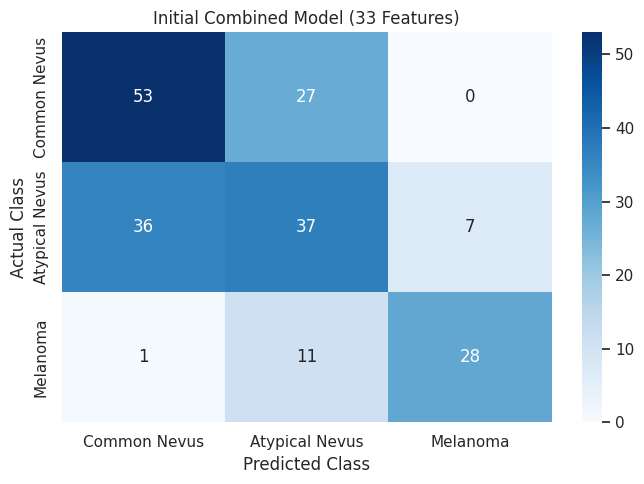

Initial Combined Classification Report:
                precision    recall  f1-score   support

  Common Nevus       0.59      0.66      0.62        80
Atypical Nevus       0.49      0.46      0.48        80
      Melanoma       0.80      0.70      0.75        40

      accuracy                           0.59       200
     macro avg       0.63      0.61      0.62       200
  weighted avg       0.59      0.59      0.59       200

Initial Accuracy: 0.59


In [ ]:
cm_initial = confusion_matrix(
    y,
    initial_predictions,
    labels=class_names
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_initial,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Initial Combined Model (33 Features)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("Initial Combined Classification Report:")
print(classification_report(
    y,
    initial_predictions,
    labels=class_names,
    target_names=class_names,
    zero_division=0
))

print("Initial Accuracy:", accuracy_score(y, initial_predictions))

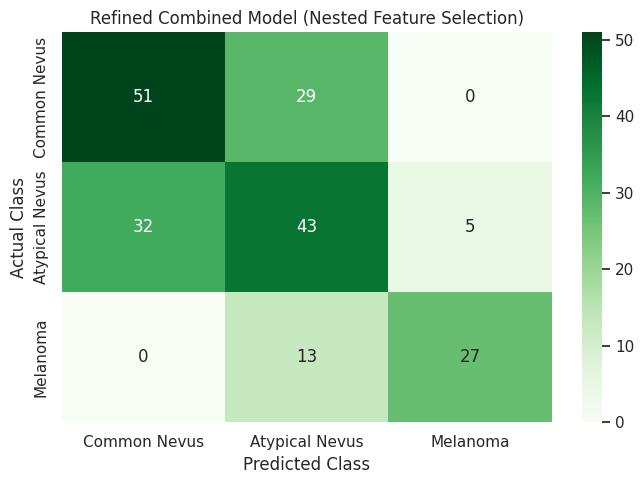

Refined Combined Classification Report:
                precision    recall  f1-score   support

  Common Nevus       0.61      0.64      0.63        80
Atypical Nevus       0.51      0.54      0.52        80
      Melanoma       0.84      0.68      0.75        40

      accuracy                           0.60       200
     macro avg       0.65      0.62      0.63       200
  weighted avg       0.62      0.60      0.61       200

Refined Accuracy: 0.605


In [ ]:
cm_refined = confusion_matrix(
    y,
    refined_predictions,
    labels=class_names
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_refined,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Refined Combined Model (Nested Feature Selection)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("Refined Combined Classification Report:")
print(classification_report(
    y,
    refined_predictions,
    labels=class_names,
    target_names=class_names,
    zero_division=0
))

print("Refined Accuracy:", accuracy_score(y, refined_predictions))

In [ ]:
np.savetxt(
    "/content/Initial_Confusion_Matrix.csv",
    cm_initial,
    delimiter=",",
    fmt="%d"
)

np.savetxt(
    "/content/Refined_Confusion_Matrix.csv",
    cm_refined,
    delimiter=",",
    fmt="%d"
)

print("Both confusion matrices saved successfully.")

Both confusion matrices saved successfully.


In [ ]:
print("Initial Confusion Matrix:")
print(cm_initial)

print("\nRefined Confusion Matrix:")
print(cm_refined)

Initial Confusion Matrix:
[[53 27  0]
 [36 37  7]
 [ 1 11 28]]

Refined Confusion Matrix:
[[51 29  0]
 [32 43  5]
 [ 0 13 27]]
